In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.preprocessing import MinMaxScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('Student Engagement_Pilot_AUGMENTED.csv')

DATA VISUALISATION

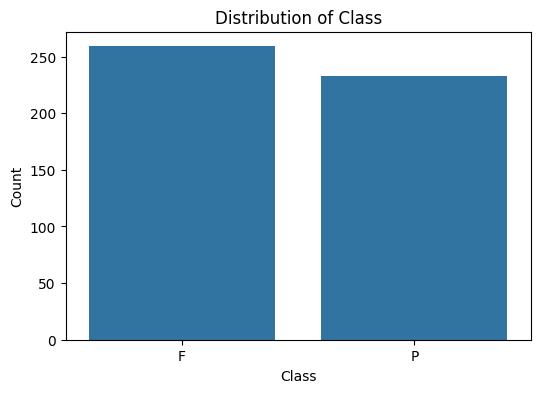

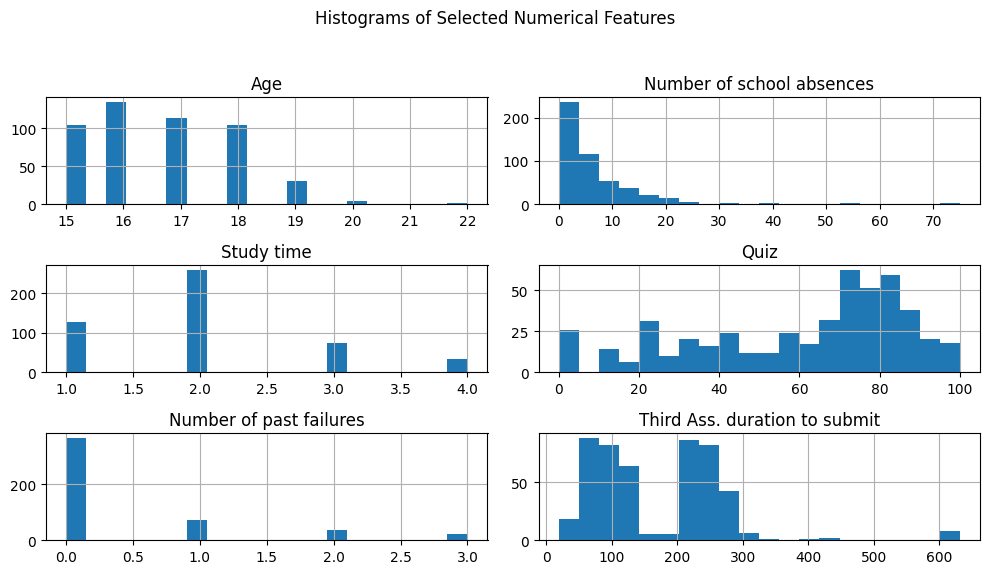

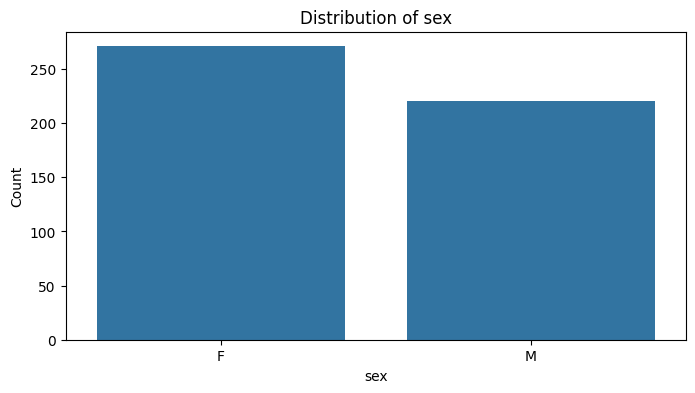

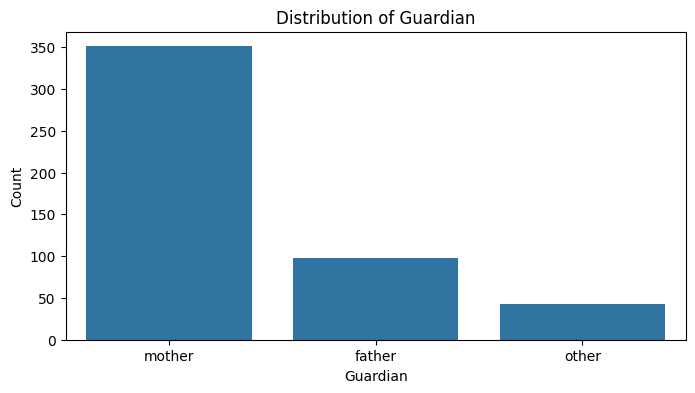

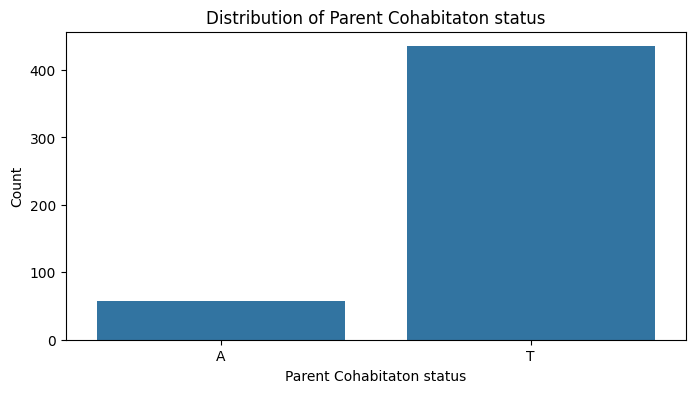

In [ ]:
# Visualize the distribution of the target variable 'Class'
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribution of Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Visualize distributions of a few numerical features
numerical_features_to_plot = ['Age', 'Number of school absences', 'Study time','Quiz', 'Number of past failures', 'Third Ass. duration to submit']
df[numerical_features_to_plot].hist(figsize=(10, 6), bins=20)
plt.suptitle('Histograms of Selected Numerical Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Visualize distributions of a few categorical features
# Ensure the renaming cell (KxTBFsk_yBv4) is run before this cell
categorical_features_to_plot = [ 'sex', 'Guardian', 'Parent Cohabitaton status']
for col in categorical_features_to_plot:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

In [ ]:
df.rename(columns={"Parent's cohabitation status": "Parent Cohabitaton status", "Mother's education": "Mother education", "Father's education": "Father education", "Mother's job": "Mother job", "Father's job": "Father job"}, inplace=True)

In [ ]:
df.drop([' ID'], axis=1, inplace=True)

In [ ]:
target = df['Class']
features = df.drop('Class', axis=1)

In [ ]:
X = features
y = target

SPLIT DATA INTO TRAIN AND TEST

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
    )

In [ ]:
# List of columns to label encode
label_encode_cols = [
    'Family size',
    'Extra school support',
    'Family support',
    'Extra paid classes',
    'Activities curricular activities',
    'Nursery attended',
    'Wants to attend higher education',
    'Internet access at home',
    'Romantic status',
    'Parent Cohabitaton status'
]

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Apply Label Encoding to the training set
for col in label_encode_cols:
    if col in X_train.columns:
        X_train[col] = label_encoder.fit_transform(X_train[col])

In [ ]:
# Apply Label Encoding to the test set
for col in label_encode_cols:
    if col in X_test.columns:
        X_test[col] = label_encoder.fit_transform(X_test[col])

In [ ]:
# List of columns to one-hot encode
onehot_encode_cols = [
    'Geographical address',
    'sex',
    'Name school',
    'Mother job',
    'Father job',
    'Reason for choice of school',
    'Guardian'
]

# Initialize OneHotEncoder
onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Apply One-Hot Encoding to the training set
X_train_encoded = onehot_encoder.fit_transform(X_train[onehot_encode_cols])
X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=onehot_encoder.get_feature_names_out(onehot_encode_cols), index=X_train.index)

# Drop original columns and concatenate the encoded columns in the training set
X_train = X_train.drop(onehot_encode_cols, axis=1)
X_train = pd.concat([X_train, X_train_encoded_df], axis=1)

# Apply One-Hot Encoding to the test set (using the fitted encoder from the training set)
X_test_encoded = onehot_encoder.transform(X_test[onehot_encode_cols])
X_test_encoded_df = pd.DataFrame(X_test_encoded, columns=onehot_encoder.get_feature_names_out(onehot_encode_cols), index=X_test.index)

# Drop original columns and concatenate the encoded columns in the test set
X_test = X_test.drop(onehot_encode_cols, axis=1)
X_test = pd.concat([X_test, X_test_encoded_df], axis=1)

In [ ]:
# List of columns to normalize (numerical columns)
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()

# Calculate mean and standard deviation from the training data
mean = X_train[numerical_cols].mean()
std = X_train[numerical_cols].std()

# Apply Z-score normalization to the training set
X_train[numerical_cols] = (X_train[numerical_cols] - mean) / std

# Apply Z-score normalization to the test set using the mean and std from the training set
X_test[numerical_cols] = (X_test[numerical_cols] - mean) / std

In [ ]:
# Apply Z-score normalization to the training set
X_train[numerical_cols] = (X_train[numerical_cols] - mean) / std

MUTUAL INFOR FEATURE SELECTION

In [ ]:
pipeline = Pipeline([
    ('feature_selector', SelectKBest(score_func=mutual_info_classif)),
])

In [ ]:
# Fit the pipeline to the training data
pipeline.fit(X_train, y_train)

# Get the selected features
selected_features_mask = pipeline.named_steps['feature_selector'].get_support()
selected_features = X_train.columns[selected_features_mask]

# Print the selected features
print("Selected Features:")
print(selected_features.tolist())

Selected Features:
['First Ass. duration to submit', 'Second Ass. duration to submit (in hours)', 'Third Ass. duration to submit', 'Ave. time to submit Ass.', 'Quiz', 'First Ass.', 'Second Ass.', 'Third Ass.', 'Course Grade', 'Total']


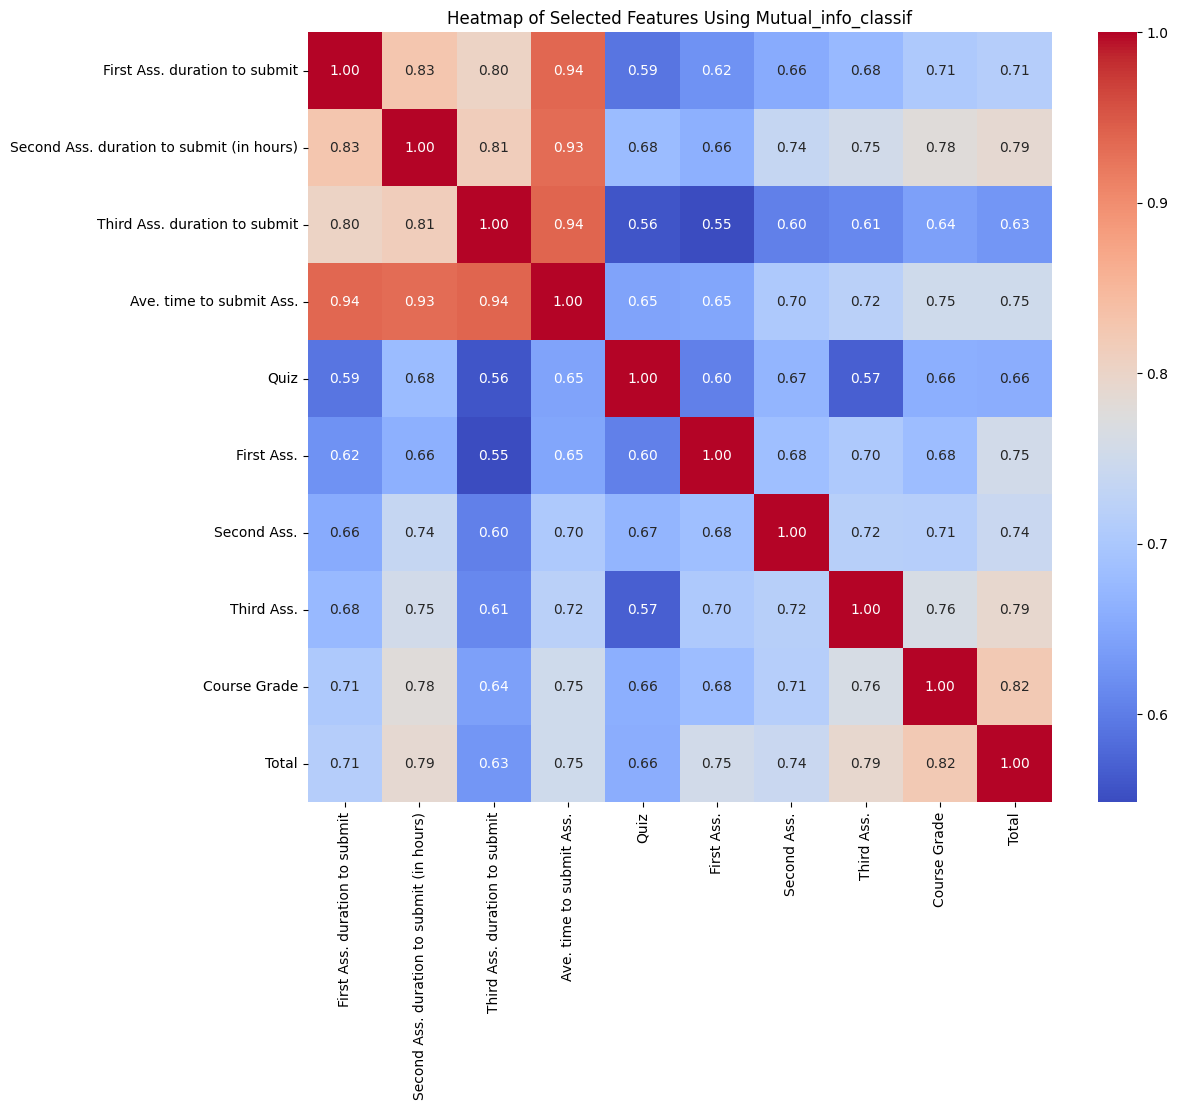

In [ ]:
# Get the subset of the training data with selected features
X_train_selected = X_train[selected_features]

# Calculate the correlation matrix
corr_matrix = X_train_selected.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Mutual_info_classif')
plt.show()


LSTM WITHOUT FEATURE SELECTION

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Test Accuracy: 0.8378
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

LSTM Model without Feature selection:
Accuracy: 0.8378
Precision: 0.8378
Recall: 0.8378
F1-measure: 0.8378

Classification Report:
              precision    recall  f1-score   support

           F       0.85      0.85      0.85        78
           P       0.83      0.83      0.83        70

    accuracy                           0.84       148
   macro avg       0.84      0.84      0.84       148
weighted avg       0.84      0.84      0.84       148



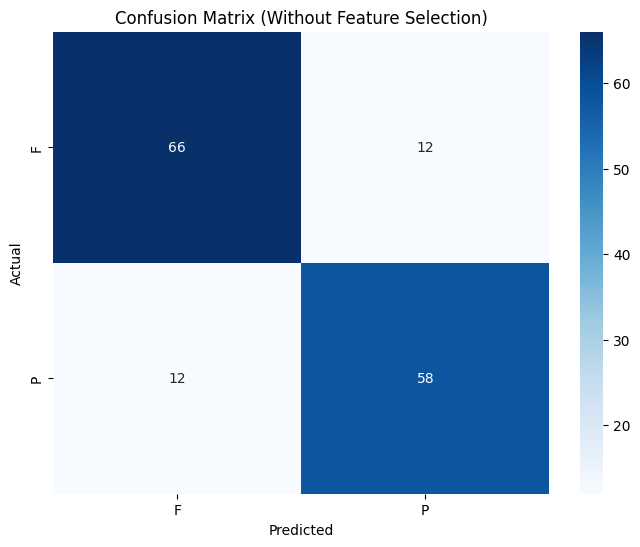

In [ ]:
np.random.seed(42)
# For a simple LSTM with one timestep per sample, we reshape:
X_train_reshaped = X_train.values.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_reshaped = X_test.values.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Label encode the target variable
label_encoder_y = LabelEncoder()
y_train_encoded = label_encoder_y.fit_transform(y_train)
y_test_encoded = label_encoder_y.transform(y_test)

# Build the LSTM model
model = Sequential()
model.add(LSTM(50, input_shape=(X_train_reshaped.shape[1], X_train_reshaped.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid')) # Output layer for binary classification

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_reshaped, y_test_encoded, verbose=0)
print(f'Test Accuracy: {accuracy:.4f}')

# Make predictions on the test set
y_pred_prob = model.predict(X_test_reshaped)
y_pred_encoded = (y_pred_prob > 0.5).astype("int32")

# Decode predictions back to original labels
y_pred = label_encoder_y.inverse_transform(y_pred_encoded.flatten())

# Calculate evaluation metrics
accuracy_rfe = accuracy_score(y_test, y_pred)
precision_rfe = precision_score(y_test, y_pred, average='weighted') # Use weighted average for multi-class/imbalanced
recall_rfe = recall_score(y_test, y_pred, average='weighted')
f1_rfe = f1_score(y_test, y_pred, average='weighted')

print("\nLSTM Model without Feature selection:")
print(f"Accuracy: {accuracy_rfe:.4f}")
print(f"Precision: {precision_rfe:.4f}")
print(f"Recall: {recall_rfe:.4f}")
print(f"F1-measure: {f1_rfe:.4f}")

# Print classification report (includes Precision, Recall, F1-score)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm_rfe = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rfe, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Without Feature Selection)')
plt.show()

LSTM MODEL WITH MUTUAL INFO FEATURE SELECTION

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Test Accuracy (Selected Features): 0.0203
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

LSTM Model with Mutual Info Features:
Accuracy: 0.0203
Precision: 0.0217
Recall: 0.0203
F1-measure: 0.0209

Classification Report (Mutual Info Features):
              precision    recall  f1-score   support

           F       0.04      0.04      0.04        78
           P       0.00      0.00      0.00        70

    accuracy                           0.02       148
   macro avg       0.02      0.02      0.02       148
weighted avg       0.02      0.02      0.02       148



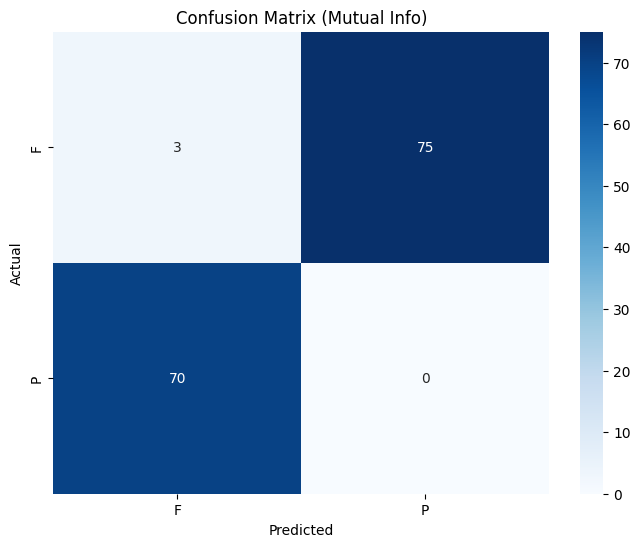

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# Get the subset of the training and test data with selected features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

# For a simple LSTM with one timestep per sample, we reshape:
X_train_selected_reshaped = X_train_selected.values.reshape((X_train_selected.shape[0], 1, X_train_selected.shape[1]))
X_test_selected_reshaped = X_test_selected.values.reshape((X_test_selected.shape[0], 1, X_test_selected.shape[1]))

# Label encode the target variable
label_encoder_y = LabelEncoder()
y_train_encoded = label_encoder_y.fit_transform(y_train)
y_test_encoded = label_encoder_y.transform(y_test)

# Build the LSTM model
model_selected = Sequential()
model_selected.add(LSTM(50, input_shape=(X_train_selected_reshaped.shape[1], X_train_selected_reshaped.shape[2])))
model_selected.add(Dropout(0.2))
model_selected.add(Dense(1, activation='sigmoid')) # Output layer for binary classification

# Compile the model
model_selected.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_selected = model_selected.fit(X_train_selected_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
loss_selected, accuracy_selected = model_selected.evaluate(X_test_selected_reshaped, y_test_encoded, verbose=0)
print(f'Test Accuracy (Selected Features): {accuracy_selected:.4f}')

# Make predictions on the test set
y_pred_prob_selected = model_selected.predict(X_test_selected_reshaped)
y_pred_encoded_selected = (y_pred_prob_selected > 0.5).astype("int32")

# Decode predictions back to original labels
y_pred_selected = label_encoder_y.inverse_transform(y_pred_encoded_selected.flatten())


# Calculate evaluation metrics
accuracy_rfe = accuracy_score(y_test, y_pred_selected)
precision_rfe = precision_score(y_test, y_pred_selected, average='weighted')
recall_rfe = recall_score(y_test, y_pred_selected, average='weighted')
f1_rfe = f1_score(y_test, y_pred_selected, average='weighted')

print("\nLSTM Model with Mutual Info Features:")
print(f"Accuracy: {accuracy_rfe:.4f}")
print(f"Precision: {precision_rfe:.4f}")
print(f"Recall: {recall_rfe:.4f}")
print(f"F1-measure: {f1_rfe:.4f}")

# Print classification report (includes Precision, Recall, F1-score)
print("\nClassification Report (Mutual Info Features):")
print(classification_report(y_test, y_pred_selected))

# Confusion Matrix
cm_rfe = confusion_matrix(y_test, y_pred_selected)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rfe, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Mutual Info)')
plt.show()

RECURSIVE FEATURE SELECTION


Recursive Feature Elimination (RFE) Results:
Selected Features (RFE):
['Logins', 'Content Reads', 'Forum Reads', 'First Ass. duration to submit', 'Quiz', 'First Ass.', 'Midterm Exam', 'Second Ass.', 'Third Ass.', 'Final Exam', 'Course Grade', 'Total', 'Age', 'Number of past failures', 'Geographical address_R', 'Geographical address_U', 'sex_F', 'sex_M', 'Name school_GP', 'Name school_MS']

Feature Ranking (RFE):
Logins                         1
Content Reads                  1
Forum Reads                    1
Second Ass.                    1
Quiz                           1
                              ..
Family size                   43
Workday alcohol consuption    44
Family support                45
Extra paid classes            46
Internet access at home       47
Length: 66, dtype: int64

Shape of X_train after RFE: (344, 20)
Shape of X_test after RFE: (148, 20)


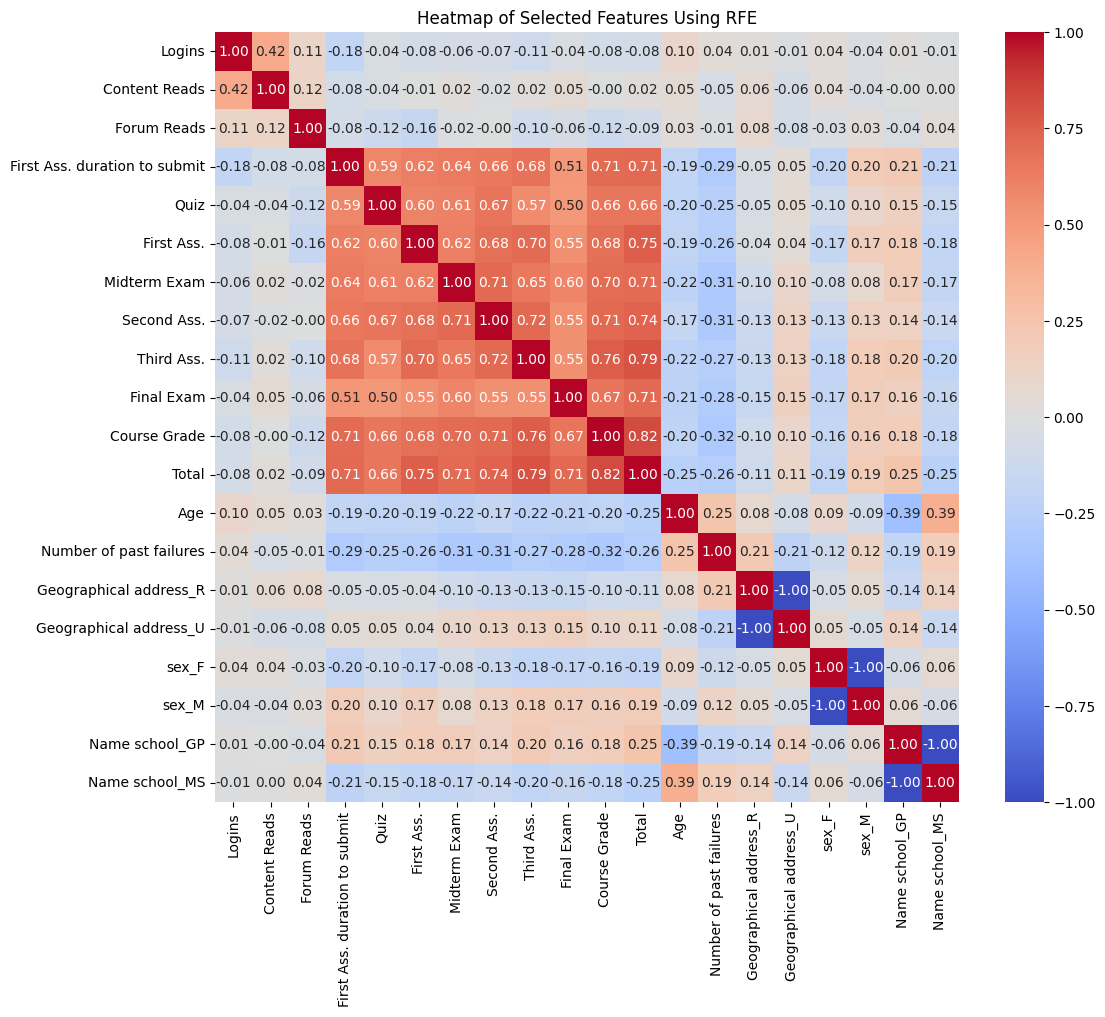

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression # Using a common estimator for RFE

estimator = LogisticRegression(solver='liblinear')
rfe = RFE(estimator=estimator, n_features_to_select=20)

# Fit RFE on the training data
rfe.fit(X_train, y_train)

# Get the selected features mask
selected_features_mask_rfe = rfe.support_

# Get the ranking of features
feature_ranking = rfe.ranking_

# Get the names of the selected features
selected_features_rfe = X_train.columns[selected_features_mask_rfe]

print("\nRecursive Feature Elimination (RFE) Results:")
print("Selected Features (RFE):")
print(selected_features_rfe.tolist())

print("\nFeature Ranking (RFE):")
# Create a Series to easily view features and their ranks
feature_ranking_series = pd.Series(feature_ranking, index=X_train.columns)
print(feature_ranking_series.sort_values())

# Get the subset of the training and testing data with selected features from RFE
X_train_rfe = X_train[selected_features_rfe]
X_test_rfe = X_test[selected_features_rfe]

print("\nShape of X_train after RFE:", X_train_rfe.shape)
print("Shape of X_test after RFE:", X_test_rfe.shape)

# Optional: Plot a heatmap of correlations for RFE selected features
corr_matrix_rfe = X_train_rfe.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_rfe, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using RFE')
plt.show()


LSTM MODEL WITH RECURSIVE FEATURE SELECTION

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/5 ━━━━━━━━━━━━━━━━━━━━ 1s 350ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step

LSTM Model with RFE Selected Features:
Accuracy: 0.8784
Precision: 0.8798
Recall: 0.8784
F1-measure: 0.8785

Classification Report (RFE):
              precision    recall  f1-score   support

           F       0.91      0.86      0.88        78
           P       0.85      0.90      0.88        70

    accuracy                           0.88       148
   macro avg       0.88      0.88      0.88       148
weighted avg       0.88      0.88      0.88       148



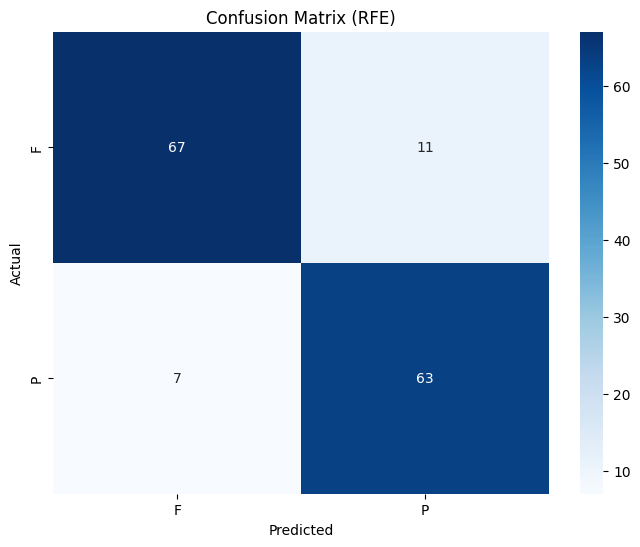

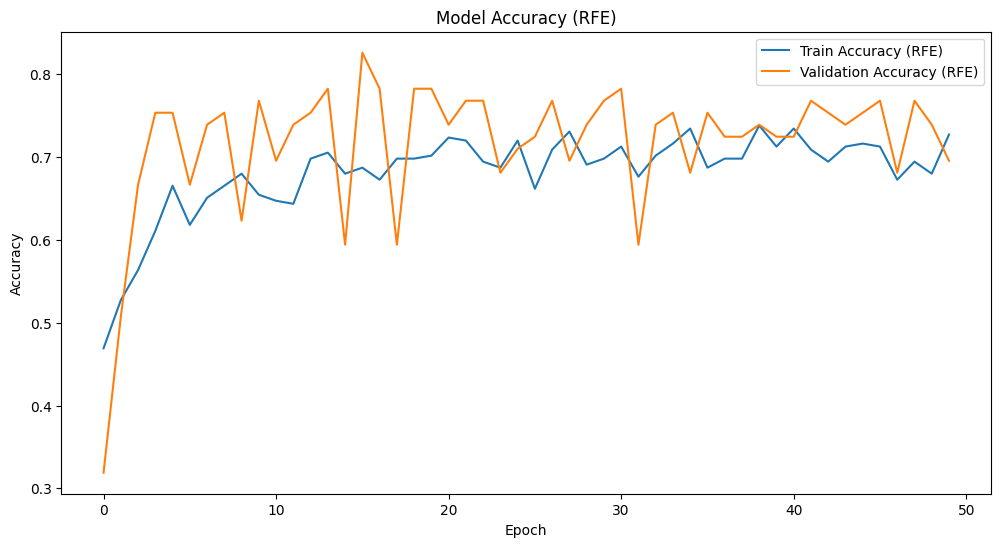

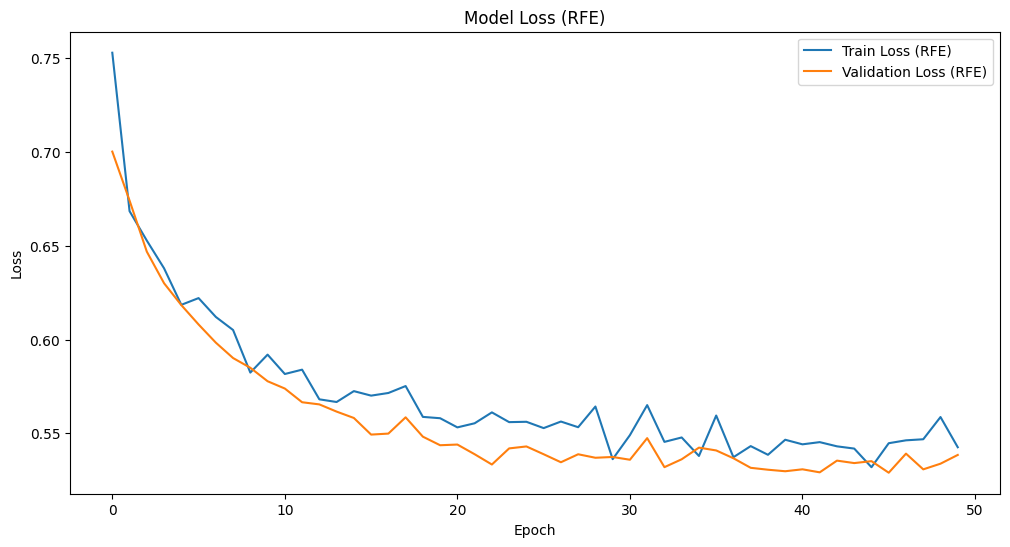

In [ ]:
np.random.seed(42)

# Since our data is tabular, we treat each sample as a single timestep
X_train_rfe_reshaped = X_train_rfe.values.reshape((X_train_rfe.shape[0], 1, X_train_rfe.shape[1]))
X_test_rfe_reshaped = X_test_rfe.values.reshape((X_test_rfe.shape[0], 1, X_test_rfe.shape[1]))

# Initialize LabelEncoder for the target variable
label_encoder_y = LabelEncoder()
y_train_encoded = label_encoder_y.fit_transform(y_train)
y_test_encoded = label_encoder_y.transform(y_test)

# Build the LSTM model
model_rfe = Sequential()
model_rfe.add(LSTM(50, activation='relu', input_shape=(X_train_rfe_reshaped.shape[1], X_train_rfe_reshaped.shape[2])))
model_rfe.add(Dropout(0.2))
model_rfe.add(Dense(1, activation='sigmoid')) # we use sigmoid for binary classification

# Compile the model
model_rfe.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_rfe = model_rfe.fit(X_train_rfe_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
y_pred_prob_rfe = model_rfe.predict(X_test_rfe_reshaped)
y_pred_encoded_rfe = (y_pred_prob_rfe > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_rfe = label_encoder_y.inverse_transform(y_pred_encoded_rfe.flatten())

# Calculate evaluation metrics
accuracy_rfe = accuracy_score(y_test, y_pred_rfe)
precision_rfe = precision_score(y_test, y_pred_rfe, average='weighted') # Use weighted average for multi-class/imbalanced
recall_rfe = recall_score(y_test, y_pred_rfe, average='weighted')
f1_rfe = f1_score(y_test, y_pred_rfe, average='weighted')

print("\nLSTM Model with RFE Selected Features:")
print(f"Accuracy: {accuracy_rfe:.4f}")
print(f"Precision: {precision_rfe:.4f}")
print(f"Recall: {recall_rfe:.4f}")
print(f"F1-measure: {f1_rfe:.4f}")

# Classification Report
print("\nClassification Report (RFE):")
print(classification_report(y_test, y_pred_rfe))

# Confusion Matrix
cm_rfe = confusion_matrix(y_test, y_pred_rfe)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rfe, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (RFE)')
plt.show()

# Plot training and validation accuracy for RFE model
plt.figure(figsize=(12, 6))
plt.plot(history_rfe.history['accuracy'], label='Train Accuracy (RFE)')
plt.plot(history_rfe.history['val_accuracy'], label='Validation Accuracy (RFE)')
plt.title('Model Accuracy (RFE)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for RFE model
plt.figure(figsize=(12, 6))
plt.plot(history_rfe.history['loss'], label='Train Loss (RFE)')
plt.plot(history_rfe.history['val_loss'], label='Validation Loss (RFE)')
plt.title('Model Loss (RFE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

LASSO FEATURE SELECTION


Lasso Feature Selection Results:
Selected Features (Lasso):
['Forum Reads', 'Forum Posts', 'Quiz reviews before submission', 'First Ass. 1 Lateness indicator', 'Second Ass. lateness indicator', 'Third Ass. lateness indicator', 'Second Ass. duration to submit (in hours)', 'Quiz', 'First Ass.', 'Midterm Exam', 'Second Ass.', 'Third Ass.', 'Final Exam', 'Course Grade', 'Total', 'Age', 'Family size', 'Parent Cohabitaton status', 'Mother education', 'Father education', 'Travel time from home to school', 'Study time', 'Number of past failures', 'Extra school support', 'Family support', 'Extra paid classes', 'Nursery attended', 'Wants to attend higher education', 'Internet access at home', 'Romantic status', 'Quantity family relationship', 'Freetime after school', 'Go out with friends', 'Workday alcohol consuption', 'Workplace alcohol consuption', 'Health status', 'Geographical address_R', 'Geographical address_U', 'sex_F', 'Name school_GP', 'Name school_MS', 'Mother job_at_home', 'Mother jo

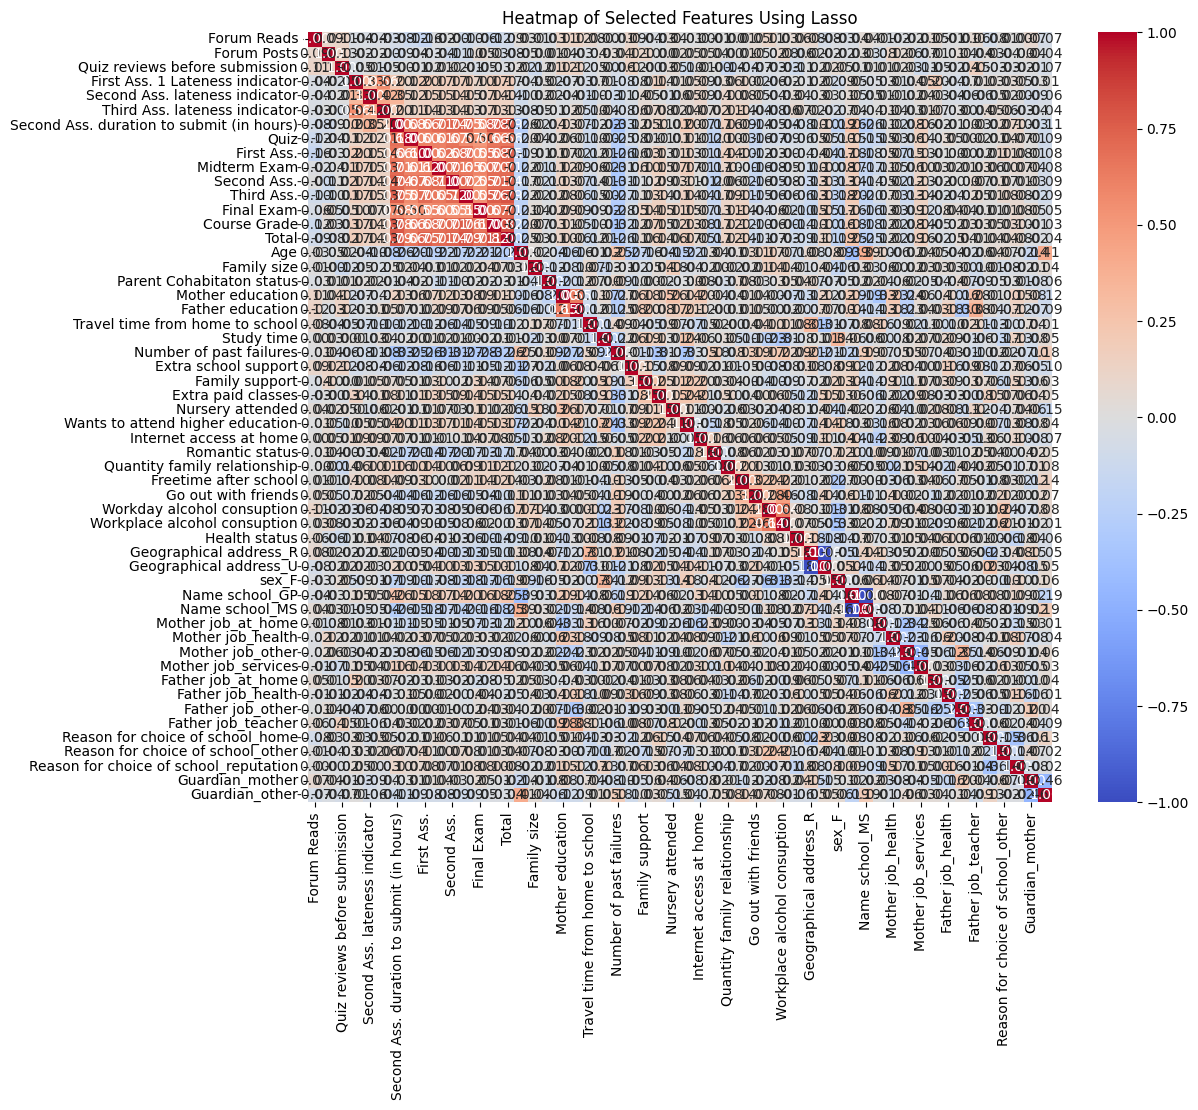

In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import LabelEncoder # Import LabelEncoder

# LASSO FEATURE SELECTION

# Initialize LabelEncoder
label_encoder_y = LabelEncoder()

# Convert target variable to numerical using LabelEncoder
y_train_encoded = label_encoder_y.fit_transform(y_train)
y_test_encoded = label_encoder_y.transform(y_test)

# max_iter is important for convergence on larger datasets
lasso = LassoCV(cv=5, random_state=42, max_iter=10000)
selector = SelectFromModel(lasso, threshold=1e-25)
selector.fit(X_train, y_train_encoded)

# Get the selected features mask
selected_features_mask_lasso = selector.get_support()

# Get the names of the selected features
selected_features_lasso = X_train.columns[selected_features_mask_lasso]

print("\nLasso Feature Selection Results:")
print("Selected Features (Lasso):")
print(selected_features_lasso.tolist())

# Get the subset of the training and testing data with selected features from Lasso
X_train_lasso = X_train[selected_features_lasso]
X_test_lasso = X_test[selected_features_lasso]

print("\nShape of X_train after Lasso:", X_train_lasso.shape)
print("Shape of X_test after Lasso:", X_test_lasso.shape)

# The coefficients are stored in the underlying estimator fitted by SelectFromModel
fitted_lasso_model = selector.estimator_
lasso_coefficients = pd.Series(fitted_lasso_model.coef_, index=X_train.columns)

print("\nLasso Coefficients for all features:")
print(lasso_coefficients.sort_values(ascending=False))

# Plot a heatmap of correlations for Lasso selected features
corr_matrix_lasso = X_train_lasso.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_lasso, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Lasso')
plt.show()

LSTM WITH LASSO

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step

LSTM Model with Lasso Selected Features:
Accuracy: 0.8311
Precision: 0.8310
Recall: 0.8311
F1-measure: 0.8310

Classification Report (Lasso):
              precision    recall  f1-score   support

           F       0.84      0.85      0.84        78
           P       0.83      0.81      0.82        70

    accuracy                           0.83       148
   macro avg       0.83      0.83      0.83       148
weighted avg       0.83      0.83      0.83       148



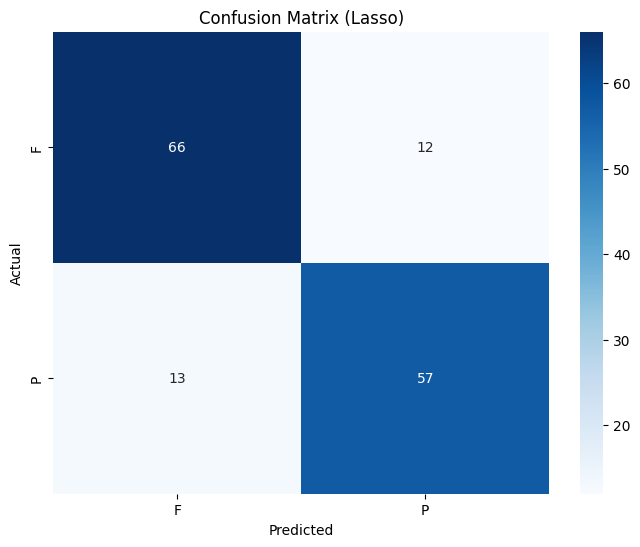

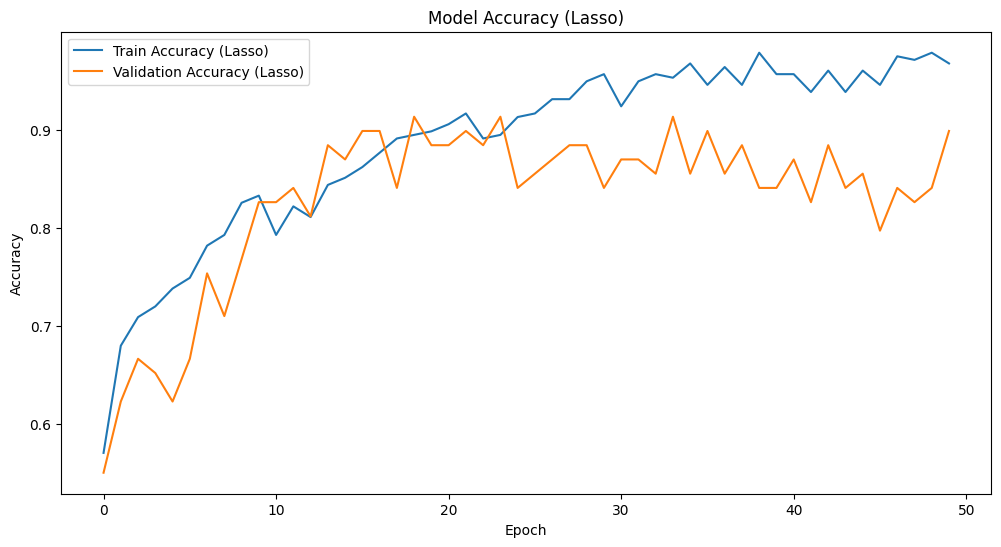

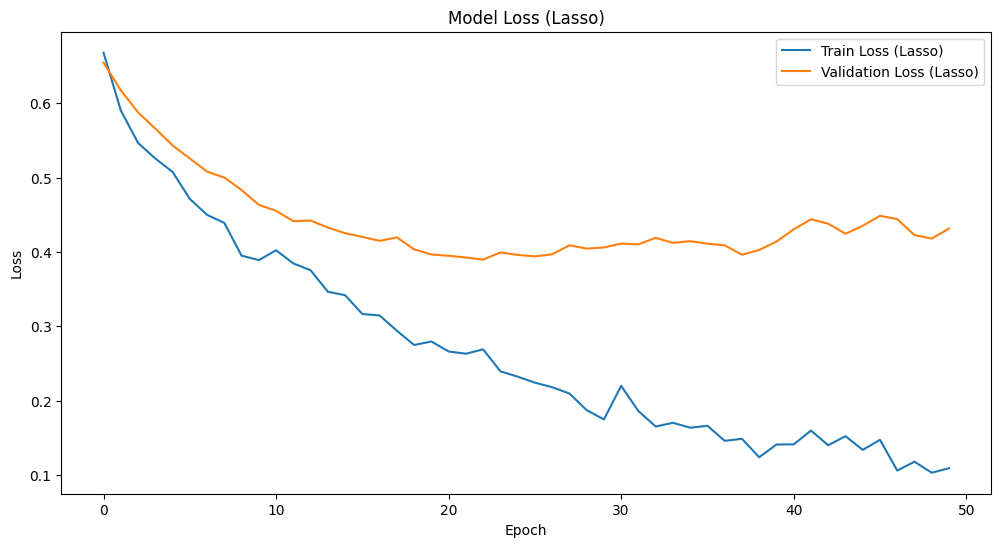

In [ ]:
np.random.seed(42)

# Since our data is tabular, we treat each sample as a single timestep
X_train_lasso_reshaped = X_train_lasso.values.reshape((X_train_lasso.shape[0], 1, X_train_lasso.shape[1]))
X_test_lasso_reshaped = X_test_lasso.values.reshape((X_test_lasso.shape[0], 1, X_test_lasso.shape[1]))

# Build the LSTM model
model_lasso = Sequential()
model_lasso.add(LSTM(50, activation='relu', input_shape=(X_train_lasso_reshaped.shape[1], X_train_lasso_reshaped.shape[2])))
model_lasso.add(Dropout(0.2))
model_lasso.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_lasso.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_lasso = model_lasso.fit(X_train_lasso_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
y_pred_prob_lasso = model_lasso.predict(X_test_lasso_reshaped)
y_pred_encoded_lasso = (y_pred_prob_lasso > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_lasso = label_encoder_y.inverse_transform(y_pred_encoded_lasso.flatten())

# Calculate evaluation metrics
accuracy_lasso = accuracy_score(y_test, y_pred_lasso)
precision_lasso = precision_score(y_test, y_pred_lasso, average='weighted') # Use weighted average for multi-class/imbalanced
recall_lasso = recall_score(y_test, y_pred_lasso, average='weighted')
f1_lasso = f1_score(y_test, y_pred_lasso, average='weighted')

print("\nLSTM Model with Lasso Selected Features:")
print(f"Accuracy: {accuracy_lasso:.4f}")
print(f"Precision: {precision_lasso:.4f}")
print(f"Recall: {recall_lasso:.4f}")
print(f"F1-measure: {f1_lasso:.4f}")

# Classification Report
print("\nClassification Report (Lasso):")
print(classification_report(y_test, y_pred_lasso))

# Confusion Matrix
cm_lasso = confusion_matrix(y_test, y_pred_lasso)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lasso, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Lasso)')
plt.show()

# Plot training and validation accuracy for Lasso model
plt.figure(figsize=(12, 6))
plt.plot(history_lasso.history['accuracy'], label='Train Accuracy (Lasso)')
plt.plot(history_lasso.history['val_accuracy'], label='Validation Accuracy (Lasso)')
plt.title('Model Accuracy (Lasso)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for Lasso model
plt.figure(figsize=(12, 6))
plt.plot(history_lasso.history['loss'], label='Train Loss (Lasso)')
plt.plot(history_lasso.history['val_loss'], label='Validation Loss (Lasso)')
plt.title('Model Loss (Lasso)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

INFORMATION GAIN


Information Gain Feature Selection Results:
Selected Features (Top 20 based on Information Gain):
['Forum Posts', 'First Ass. 1 Lateness indicator', 'First Ass. duration to submit', 'Second Ass. duration to submit (in hours)', 'Third Ass. duration to submit', 'Ave. time to submit Ass.', 'Quiz', 'First Ass.', 'Midterm Exam', 'Second Ass.', 'Third Ass.', 'Final Exam', 'Course Grade', 'Total', 'Number of past failures', 'Family support', 'Workday alcohol consuption', 'Geographical address_U', 'Name school_GP', 'Name school_MS']

Information Gain Scores for Features:
Ave. time to submit Ass.                     0.668092
Second Ass. duration to submit (in hours)    0.652874
Course Grade                                 0.633161
Total                                        0.619669
Second Ass.                                  0.596702
                                               ...   
Father job_teacher                           0.000000
Reason for choice of school_other            0.0000

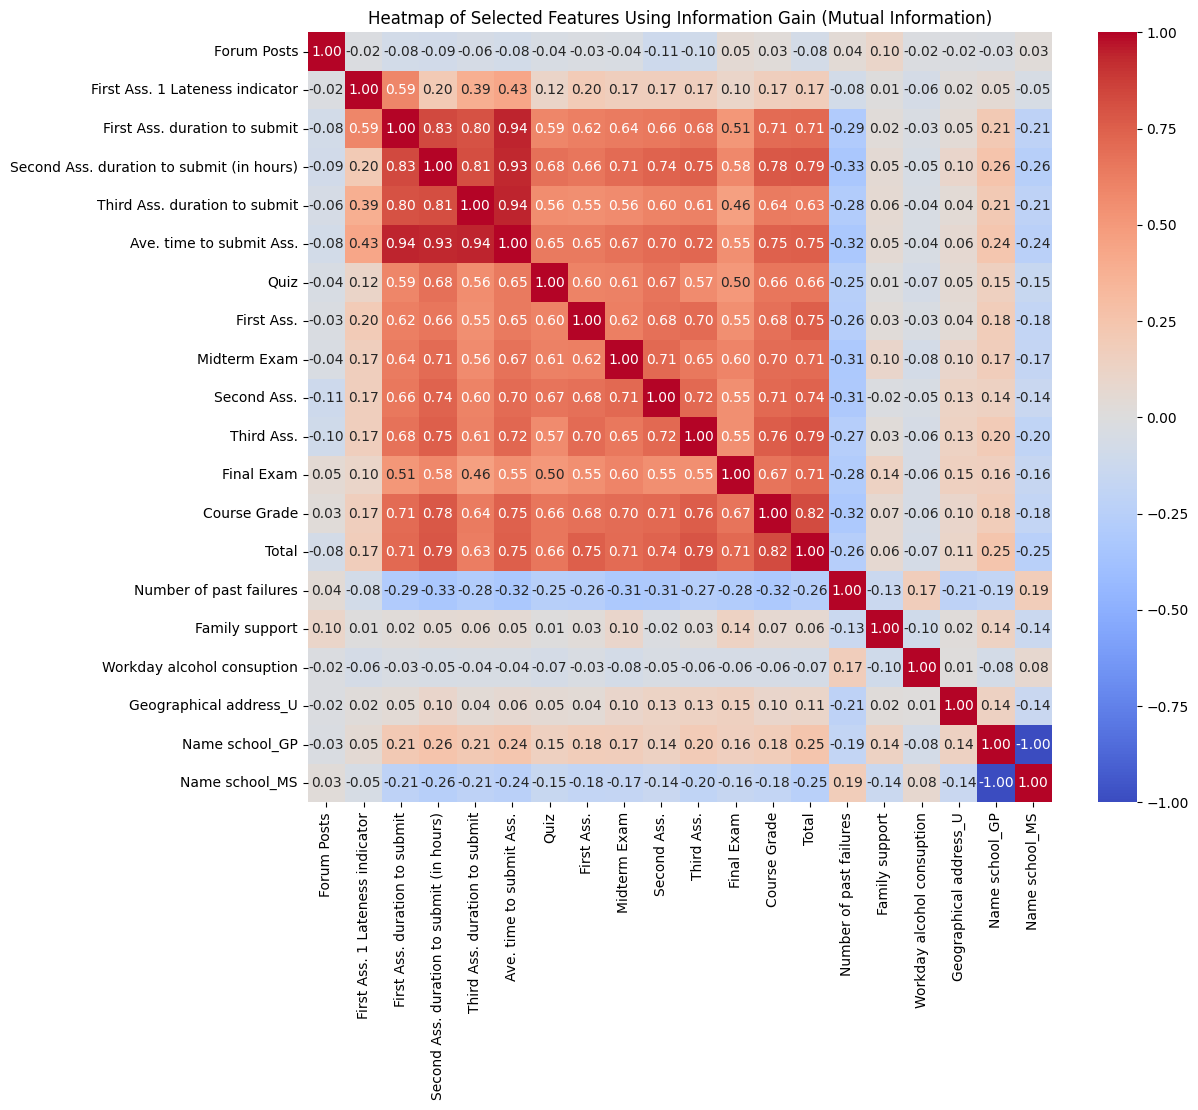

In [ ]:
k_features_to_select = 20  # Example: Select the top 20 features

info_gain_selector = SelectKBest(score_func=mutual_info_classif, k=k_features_to_select)

# Fit the selector on the training data
info_gain_selector.fit(X_train, y_train)

# Get the selected features mask
selected_features_mask_info_gain = info_gain_selector.get_support()

# Get the scores (mutual information values) for all features
feature_scores = info_gain_selector.scores_

# Get the names of the selected features
selected_features_info_gain = X_train.columns[selected_features_mask_info_gain]

print("\nInformation Gain Feature Selection Results:")
print(f"Selected Features (Top {k_features_to_select} based on Information Gain):")
print(selected_features_info_gain.tolist())

print("\nInformation Gain Scores for Features:")
# Create a Series to easily view features and their scores
feature_scores_series = pd.Series(feature_scores, index=X_train.columns)
print(feature_scores_series.sort_values(ascending=False))

# Get the subset of the training and testing data with selected features from Information Gain
X_train_info_gain = X_train[selected_features_info_gain]
X_test_info_gain = X_test[selected_features_info_gain]

print("\nShape of X_train after Information Gain selection:", X_train_info_gain.shape)
print("Shape of X_test after Information Gain selection:", X_test_info_gain.shape)

# Optional: Plot a heatmap of correlations for Information Gain selected features
corr_matrix_info_gain = X_train_info_gain.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_info_gain, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Information Gain (Mutual Information)')
plt.show()

LSTM WITH INFORMATION GAIN

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step

LSTM Model with Information Gain Selected Features:
Accuracy: 0.6081
Precision: 0.6523
Recall: 0.6081
F1-measure: 0.5894

Classification Report (Information Gain):
              precision    recall  f1-score   support

           F       0.74      0.40      0.52        78
           P       0.56      0.84      0.67        70

    accuracy                           0.61       148
   macro avg       0.65      0.62      0.59       148
weighted avg       0.65      0.61      0.59       148



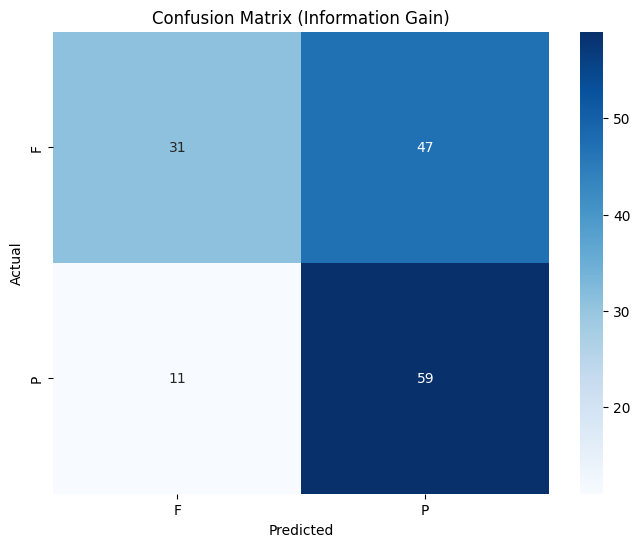

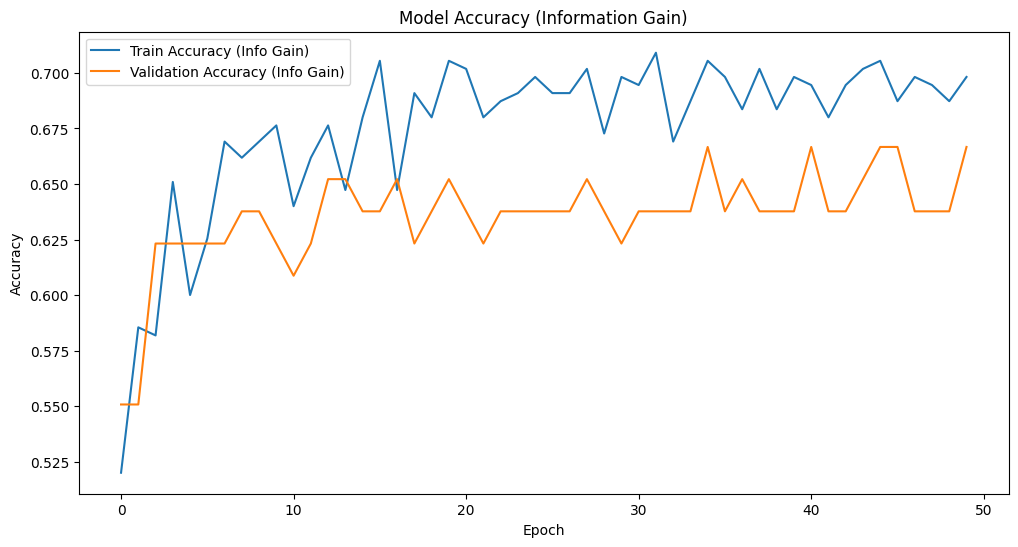

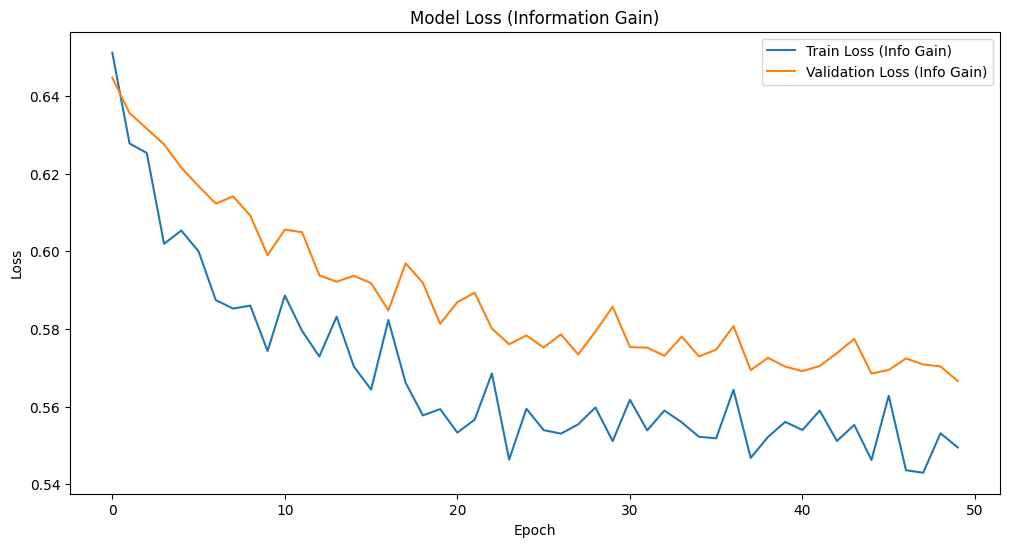

In [ ]:
np.random.seed(42)

# Reshape the data for LSTM (samples, timesteps, features)
X_train_info_gain_reshaped = X_train_info_gain.values.reshape((X_train_info_gain.shape[0], 1, X_train_info_gain.shape[1]))
X_test_info_gain_reshaped = X_test_info_gain.values.reshape((X_test_info_gain.shape[0], 1, X_test_info_gain.shape[1]))

# Build the LSTM model
model_info_gain = Sequential()
model_info_gain.add(LSTM(50, activation='relu', input_shape=(X_train_info_gain_reshaped.shape[1], X_train_info_gain_reshaped.shape[2])))
model_info_gain.add(Dropout(0.2))
model_info_gain.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_info_gain.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_info_gain = model_info_gain.fit(X_train_info_gain_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
y_pred_prob_info_gain = model_info_gain.predict(X_test_info_gain_reshaped)
y_pred_encoded_info_gain = (y_pred_prob_info_gain > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_info_gain = label_encoder_y.inverse_transform(y_pred_encoded_info_gain.flatten())

# Calculate evaluation metrics
accuracy_info_gain = accuracy_score(y_test, y_pred_info_gain)
precision_info_gain = precision_score(y_test, y_pred_info_gain, average='weighted') # Use weighted average for multi-class/imbalanced
recall_info_gain = recall_score(y_test, y_pred_info_gain, average='weighted')
f1_info_gain = f1_score(y_test, y_pred_info_gain, average='weighted')

print("\nLSTM Model with Information Gain Selected Features:")
print(f"Accuracy: {accuracy_info_gain:.4f}")
print(f"Precision: {precision_info_gain:.4f}")
print(f"Recall: {recall_info_gain:.4f}")
print(f"F1-measure: {f1_info_gain:.4f}")

# Classification Report
print("\nClassification Report (Information Gain):")
print(classification_report(y_test, y_pred_info_gain))

# Confusion Matrix
cm_info_gain = confusion_matrix(y_test, y_pred_info_gain)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_info_gain, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Information Gain)')
plt.show()

# Plot training and validation accuracy for Information Gain model
plt.figure(figsize=(12, 6))
plt.plot(history_info_gain.history['accuracy'], label='Train Accuracy (Info Gain)')
plt.plot(history_info_gain.history['val_accuracy'], label='Validation Accuracy (Info Gain)')
plt.title('Model Accuracy (Information Gain)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for Information Gain model
plt.figure(figsize=(12, 6))
plt.plot(history_info_gain.history['loss'], label='Train Loss (Info Gain)')
plt.plot(history_info_gain.history['val_loss'], label='Validation Loss (Info Gain)')
plt.title('Model Loss (Information Gain)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


CHI_SQUARED FEATURE SELECTION


Chi-Squared Feature Selection Results:
Selected Features (Top 20 based on Chi-Squared):
['First Ass. 1 Lateness indicator', 'Second Ass. lateness indicator', 'Third Ass. lateness indicator', 'First Ass. duration to submit', 'Second Ass. duration to submit (in hours)', 'Third Ass. duration to submit', 'Ave. time to submit Ass.', 'Quiz', 'First Ass.', 'Midterm Exam', 'Second Ass.', 'Third Ass.', 'Final Exam', 'Course Grade', 'Total', 'Number of past failures', 'Extra school support', 'Romantic status', 'Name school_MS', 'Mother job_services']

Chi-Squared Scores for Features:
Second Ass. duration to submit (in hours)    55.224378
Ave. time to submit Ass.                     34.236294
Third Ass.                                   28.135147
First Ass. duration to submit                25.678714
Course Grade                                 25.356004
                                               ...    
Reason for choice of school_home              0.010937
Study time                       

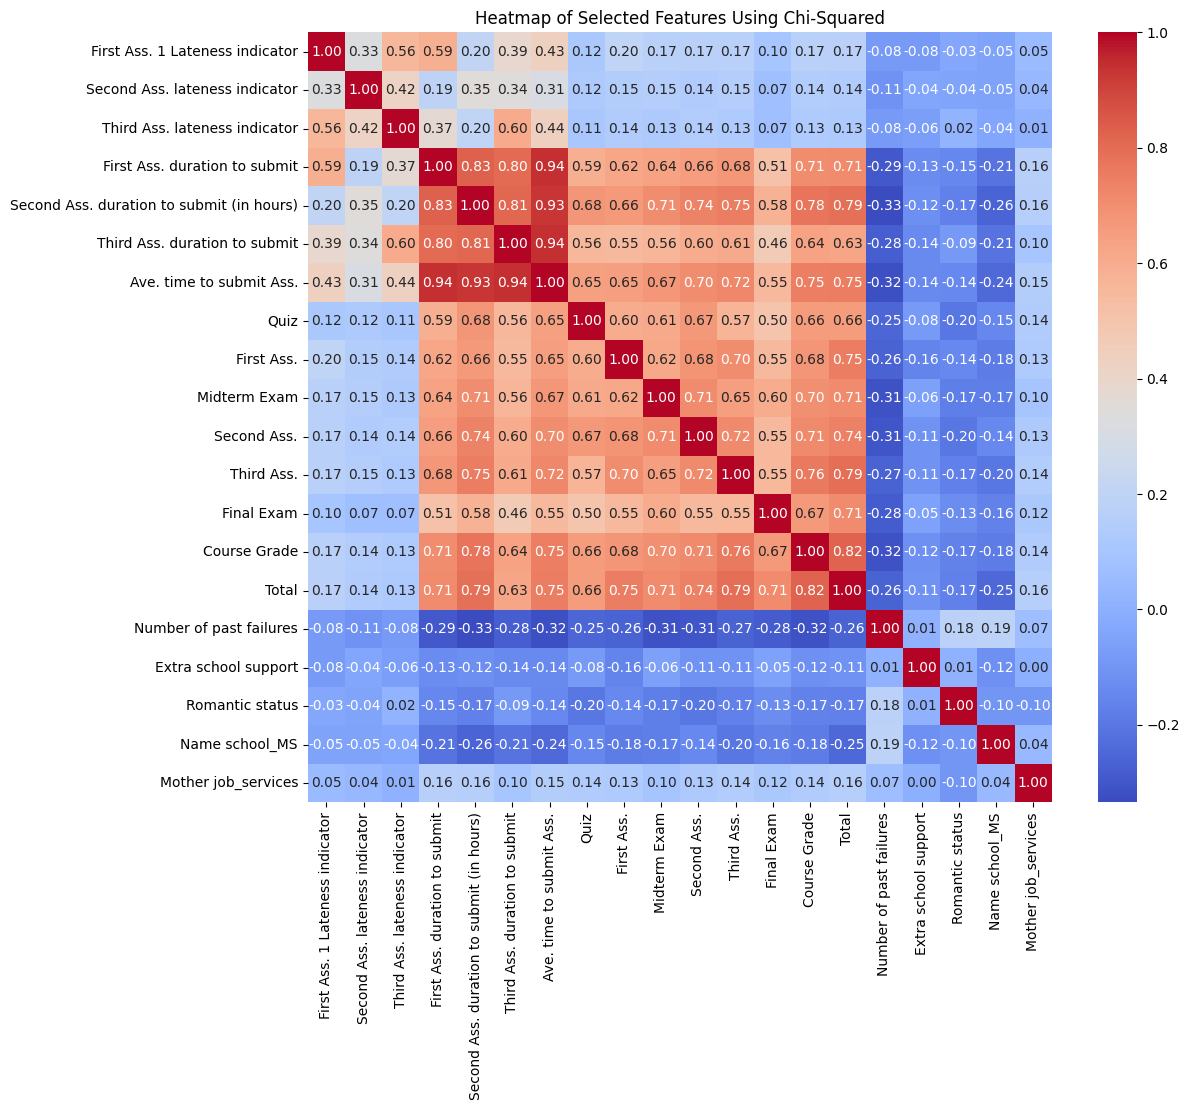

In [ ]:
scaler_chi2 = MinMaxScaler()
X_train_scaled_for_chi2 = scaler_chi2.fit_transform(X_train)
X_test_scaled_for_chi2 = scaler_chi2.transform(X_test) # Use the same scaler fitted on training data

# Convert scaled arrays back to DataFrames to keep column names
X_train_scaled_for_chi2_df = pd.DataFrame(X_train_scaled_for_chi2, columns=X_train.columns, index=X_train.index)
X_test_scaled_for_chi2_df = pd.DataFrame(X_test_scaled_for_chi2, columns=X_test.columns, index=X_test.index)

# chi2 expects a numerical target. Our 'Class' target needs to be numerical.

k_features_to_select_chi2 = 20 # Example: Select the top 20 features

chi2_selector = SelectKBest(score_func=chi2, k=k_features_to_select_chi2)

# Fit the selector on the scaled training data and encoded target
# chi2 requires non-negative features and a numerical target.
chi2_selector.fit(X_train_scaled_for_chi2_df, y_train_encoded)

# Get the selected features mask
selected_features_mask_chi2 = chi2_selector.get_support()

# Get the scores (chi-squared values) for all features
feature_scores_chi2 = chi2_selector.scores_

# Get the names of the selected features
selected_features_chi2 = X_train_scaled_for_chi2_df.columns[selected_features_mask_chi2]

print("\nChi-Squared Feature Selection Results:")
print(f"Selected Features (Top {k_features_to_select_chi2} based on Chi-Squared):")
print(selected_features_chi2.tolist())

print("\nChi-Squared Scores for Features:")
# Create a Series to easily view features and their scores
feature_scores_series_chi2 = pd.Series(feature_scores_chi2, index=X_train_scaled_for_chi2_df.columns)
# Sort by scores in descending order to see the most important features first
print(feature_scores_series_chi2.sort_values(ascending=False))

# Get the subset of the original training and testing data with selected features
X_train_chi2 = X_train[selected_features_chi2]
X_test_chi2 = X_test[selected_features_chi2]


print("\nShape of X_train after Chi-Squared selection:", X_train_chi2.shape)
print("Shape of X_test after Chi-Squared selection:", X_test_chi2.shape)

# Optional: Plot a heatmap of correlations for Chi-Squared selected features
corr_matrix_chi2 = X_train_chi2.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_chi2, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Chi-Squared')
plt.show()


LSTM WITH CHI SQUARE

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step

LSTM Model with Chi-Squared Selected Features:
Accuracy: 0.6689
Precision: 0.7415
Recall: 0.6689
F1-measure: 0.6498

Classification Report (Chi-Squared):
              precision    recall  f1-score   support

           F       0.87      0.44      0.58        78
           P       0.60      0.93      0.73        70

    accuracy                           0.67       148
   macro avg       0.73      0.68      0.65       148
weighted avg       0.74      0.67      0.65       148



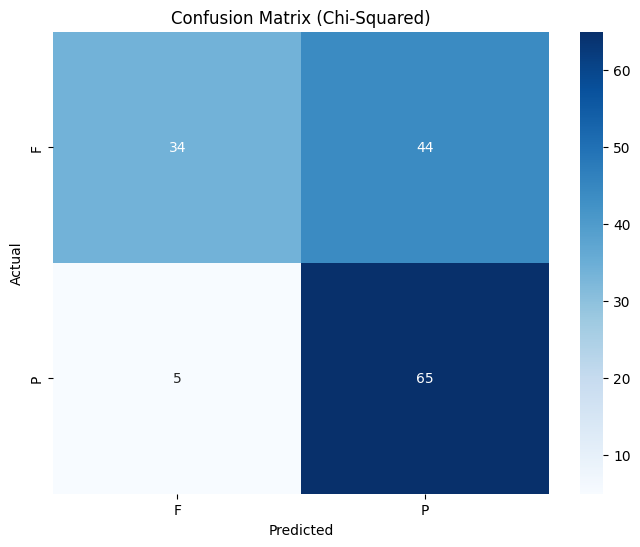

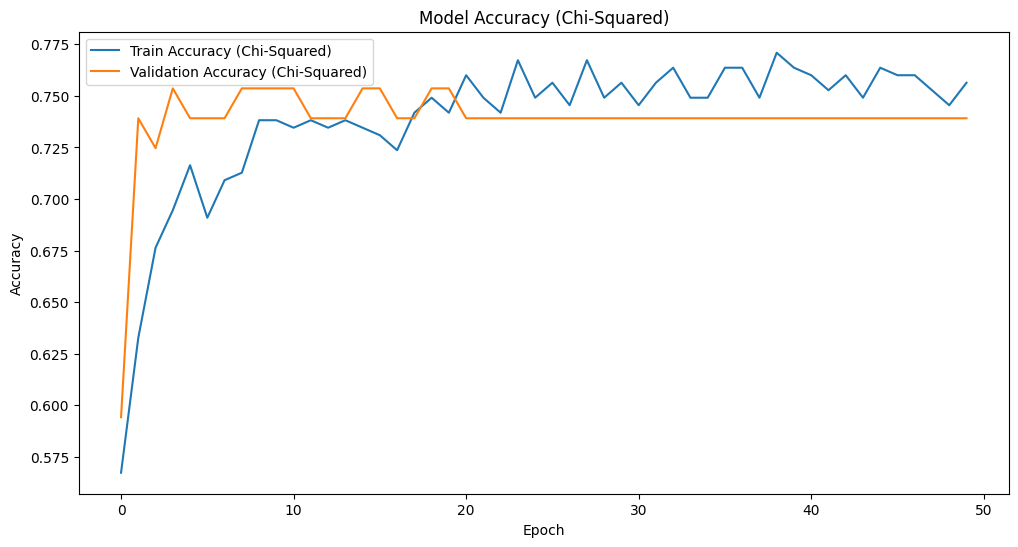

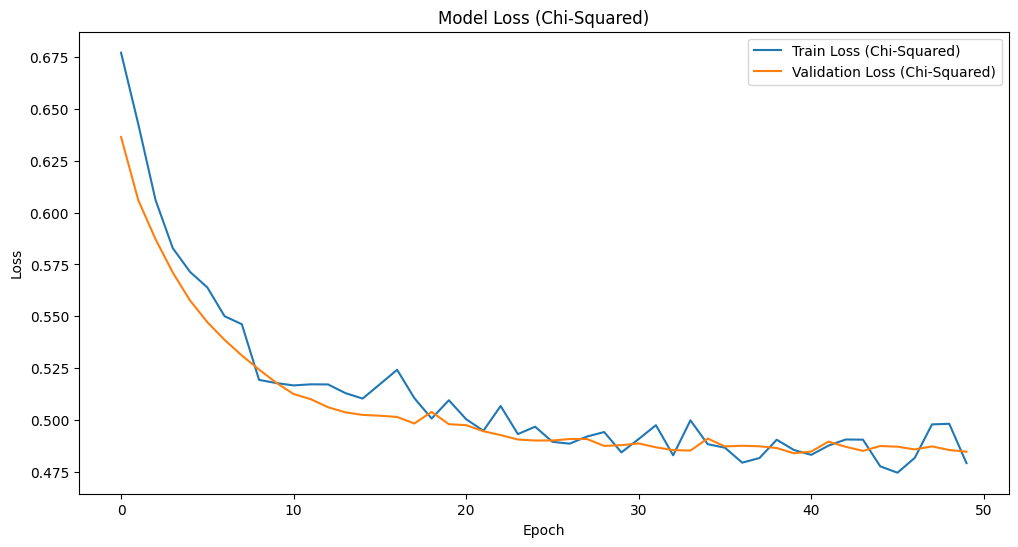

In [ ]:
np.random.seed(42)

# Reshape the data for LSTM (samples, timesteps, features)
X_train_chi2_reshaped = X_train_chi2.values.reshape((X_train_chi2.shape[0], 1, X_train_chi2.shape[1]))
X_test_chi2_reshaped = X_test_chi2.values.reshape((X_test_chi2.shape[0], 1, X_test_chi2.shape[1]))

# Build the LSTM model
model_chi2 = Sequential()
model_chi2.add(LSTM(50, activation='relu', input_shape=(X_train_chi2_reshaped.shape[1], X_train_chi2_reshaped.shape[2])))
model_chi2.add(Dropout(0.2))
model_chi2.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_chi2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_chi2 = model_chi2.fit(X_train_chi2_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
y_pred_prob_chi2 = model_chi2.predict(X_test_chi2_reshaped)
y_pred_encoded_chi2 = (y_pred_prob_chi2 > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_chi2 = label_encoder_y.inverse_transform(y_pred_encoded_chi2.flatten())

# Calculate evaluation metrics
accuracy_chi2 = accuracy_score(y_test, y_pred_chi2)
precision_chi2 = precision_score(y_test, y_pred_chi2, average='weighted') # Use weighted average for multi-class/imbalanced
recall_chi2 = recall_score(y_test, y_pred_chi2, average='weighted')
f1_chi2 = f1_score(y_test, y_pred_chi2, average='weighted')

print("\nLSTM Model with Chi-Squared Selected Features:")
print(f"Accuracy: {accuracy_chi2:.4f}")
print(f"Precision: {precision_chi2:.4f}")
print(f"Recall: {recall_chi2:.4f}")
print(f"F1-measure: {f1_chi2:.4f}")

# Classification Report
print("\nClassification Report (Chi-Squared):")
print(classification_report(y_test, y_pred_chi2))

# Confusion Matrix
cm_chi2 = confusion_matrix(y_test, y_pred_chi2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_chi2, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Chi-Squared)')
plt.show()

# Plot training and validation accuracy for Chi-Squared model
plt.figure(figsize=(12, 6))
plt.plot(history_chi2.history['accuracy'], label='Train Accuracy (Chi-Squared)')
plt.plot(history_chi2.history['val_accuracy'], label='Validation Accuracy (Chi-Squared)')
plt.title('Model Accuracy (Chi-Squared)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for Chi-Squared model
plt.figure(figsize=(12, 6))
plt.plot(history_chi2.history['loss'], label='Train Loss (Chi-Squared)')
plt.plot(history_chi2.history['val_loss'], label='Validation Loss (Chi-Squared)')
plt.title('Model Loss (Chi-Squared)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


LSTM WITH PCA


Explained Variance Ratio by each Principal Component:
[1.82026180e-01 9.05605521e-02 6.42910497e-02 5.89528943e-02
 5.42582700e-02 5.13952728e-02 4.40238823e-02 4.19997677e-02
 3.90517099e-02 3.50963405e-02 3.24710475e-02 3.10415226e-02
 2.58053336e-02 2.41916752e-02 2.31501123e-02 2.18915059e-02
 2.00445407e-02 1.62290710e-02 1.50716333e-02 1.48477858e-02
 1.34688938e-02 1.24224183e-02 1.10970698e-02 1.05840522e-02
 9.38107642e-03 8.66150653e-03 7.37246061e-03 6.68394971e-03
 5.90417066e-03 5.18218031e-03 4.69809477e-03 3.60295080e-03
 2.83789898e-03 2.39322276e-03 2.03562565e-03 1.52075970e-03
 1.47109314e-03 1.12794736e-03 1.03565416e-03 6.73650716e-04
 5.19831800e-04 4.51994173e-04 3.98208504e-04 3.16029327e-05
 1.90951209e-05 1.51926362e-05 2.00037525e-06 1.53727563e-06
 1.24277510e-06 1.10452836e-06 1.03877192e-06 7.57490562e-07
 6.41893690e-07 6.09919108e-07 1.61265687e-07 1.32255484e-07
 1.59332188e-08 9.50810707e-09 1.46165103e-26 3.43403026e-33
 2.27637205e-33 1.76869681e-33

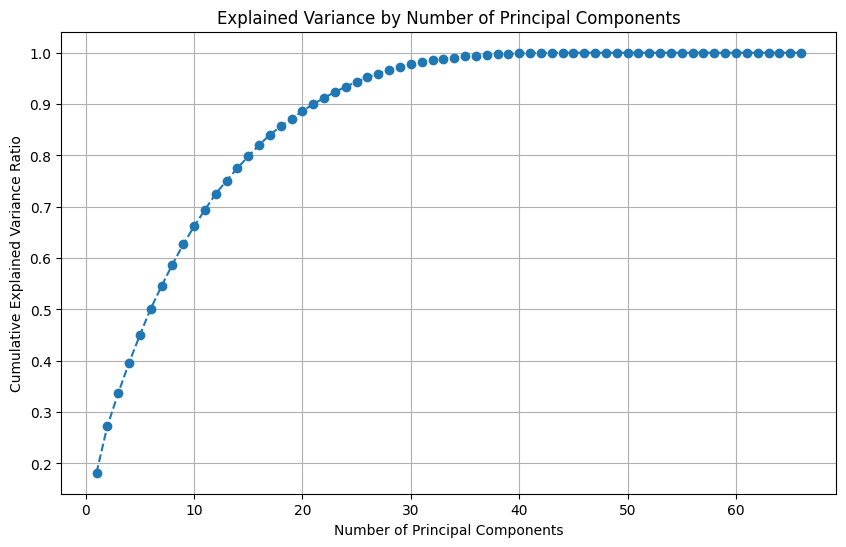


Number of components to retain 95% variance: 26

Shape of X_train after PCA: (344, 26)
Shape of X_test after PCA: (148, 26)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step

LSTM Model with PCA Transformed Features:
Accuracy: 0.6284
Precision: 0.6276
Recall: 0.6284
F1-measure: 0.6266

Classification Report (PCA):
              precision    recall  f1-score   support

           F       0.64      0.69      0.66        78
           P       0.62      0.56      0.59        70

    accuracy                           0.63       148
   macro avg       0.63      0.62      0.62       148
weighted avg       0.63      0.63      0.63       148



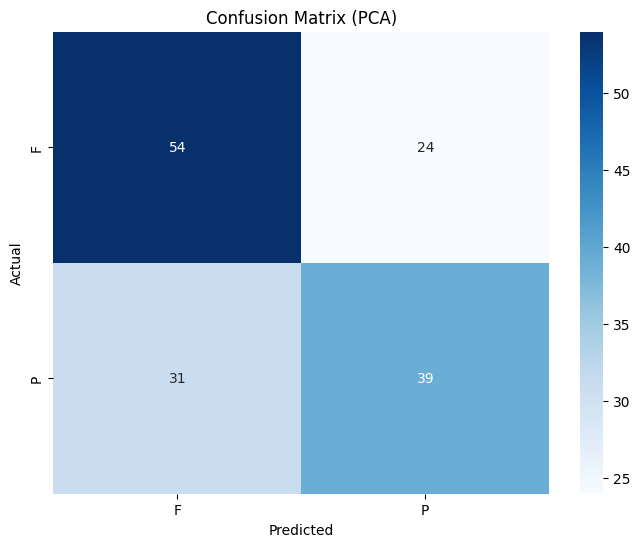

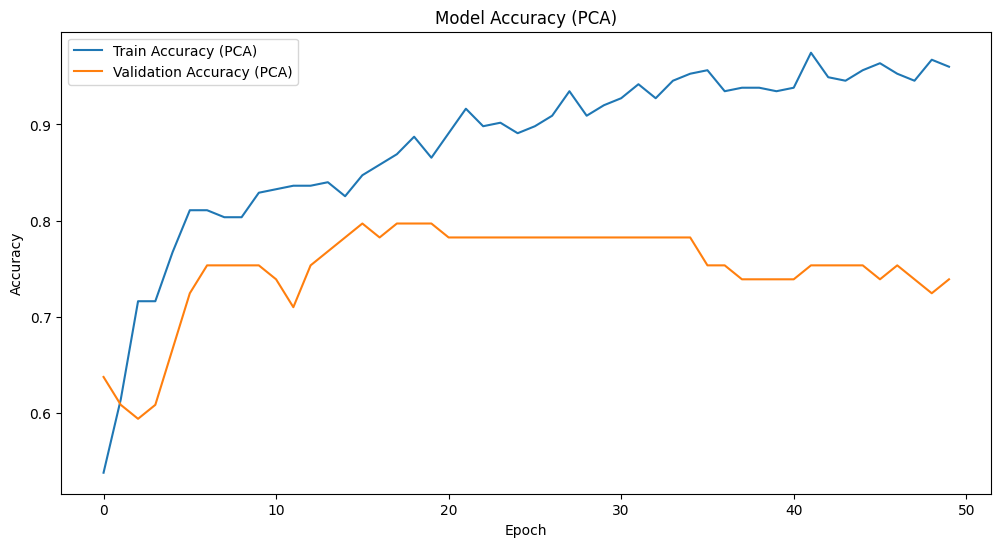

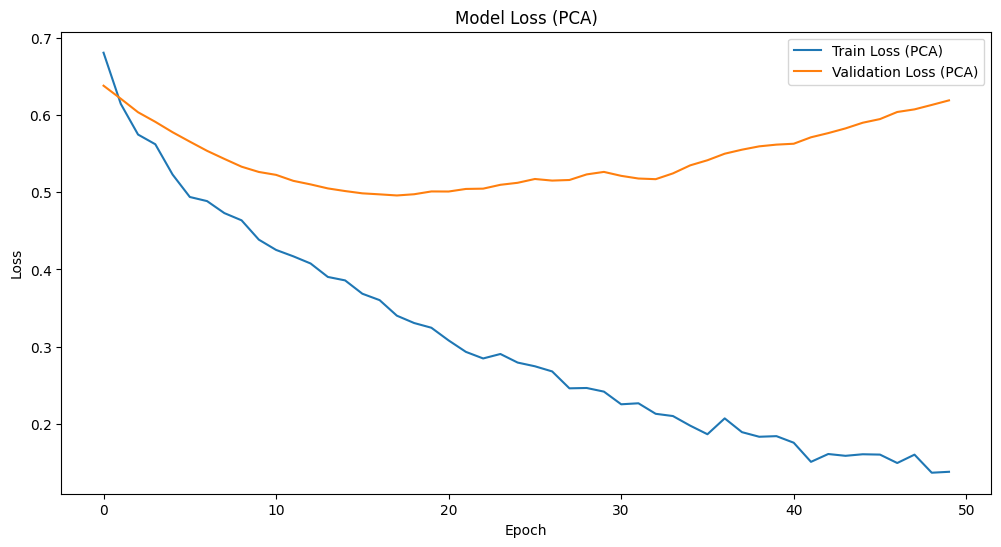

In [ ]:
from sklearn.decomposition import PCA

# Initialize PCA
pca = PCA()

# Fit PCA on the scaled training data
pca.fit(X_train)

# Explained variance ratio by each component
explained_variance_ratio = pca.explained_variance_ratio_
print("\nExplained Variance Ratio by each Principal Component:")
print(explained_variance_ratio)

# Cumulative explained variance ratio
cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio)
print("\nCumulative Explained Variance Ratio:")
print(cumulative_explained_variance_ratio)

# Plot explained variance
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_explained_variance_ratio, marker='o', linestyle='--')
plt.title('Explained Variance by Number of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.grid(True)
plt.show()

# Determine the number of components to keep (e.g., retain 95% variance)
n_components_to_keep = np.argmax(cumulative_explained_variance_ratio >= 0.95) + 1
print(f"\nNumber of components to retain 95% variance: {n_components_to_keep}")

# Now, apply PCA with the selected number of components
pca_final = PCA(n_components=n_components_to_keep)

# Transform the training and test data using the fitted PCA
X_train_pca = pca_final.fit_transform(X_train)
X_test_pca = pca_final.transform(X_test)

print("\nShape of X_train after PCA:", X_train_pca.shape)
print("Shape of X_test after PCA:", X_test_pca.shape)

# LSTM MODEL WITH PCA TRANSFORMED FEATURES

np.random.seed(42)

# Reshape the data for LSTM (samples, timesteps, features)
X_train_pca_reshaped = X_train_pca.reshape((X_train_pca.shape[0], 1, X_train_pca.shape[1]))
X_test_pca_reshaped = X_test_pca.reshape((X_test_pca.shape[0], 1, X_test_pca.shape[1]))

# Build the LSTM model
model_pca = Sequential()
model_pca.add(LSTM(50, activation='relu', input_shape=(X_train_pca_reshaped.shape[1], X_train_pca_reshaped.shape[2])))
model_pca.add(Dropout(0.2))
model_pca.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_pca.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history_pca = model_pca.fit(X_train_pca_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
y_pred_prob_pca = model_pca.predict(X_test_pca_reshaped)
y_pred_encoded_pca = (y_pred_prob_pca > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_pca = label_encoder_y.inverse_transform(y_pred_encoded_pca.flatten())

# Calculate evaluation metrics
accuracy_pca = accuracy_score(y_test, y_pred_pca)
precision_pca = precision_score(y_test, y_pred_pca, average='weighted') # Use weighted average for multi-class/imbalanced
recall_pca = recall_score(y_test, y_pred_pca, average='weighted')
f1_pca = f1_score(y_test, y_pred_pca, average='weighted')

print("\nLSTM Model with PCA Transformed Features:")
print(f"Accuracy: {accuracy_pca:.4f}")
print(f"Precision: {precision_pca:.4f}")
print(f"Recall: {recall_pca:.4f}")
print(f"F1-measure: {f1_pca:.4f}")

# Classification Report
print("\nClassification Report (PCA):")
print(classification_report(y_test, y_pred_pca))

# Confusion Matrix
cm_pca = confusion_matrix(y_test, y_pred_pca)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (PCA)')
plt.show()

# Plot training and validation accuracy for PCA model
plt.figure(figsize=(12, 6))
plt.plot(history_pca.history['accuracy'], label='Train Accuracy (PCA)')
plt.plot(history_pca.history['val_accuracy'], label='Validation Accuracy (PCA)')
plt.title('Model Accuracy (PCA)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for PCA model
plt.figure(figsize=(12, 6))
plt.plot(history_pca.history['loss'], label='Train Loss (PCA)')
plt.plot(history_pca.history['val_loss'], label='Validation Loss (PCA)')
plt.title('Model Loss (PCA)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


Starting Sequential Feature Selection (Forward Selection)... This may take some time.

Sequential Feature Selection (SFS) Results:
Selected Features (SFS, Forward Selection):
['Logins', 'Content Reads', 'Forum Reads', 'Quiz reviews before submission', 'First Ass. 1 Lateness indicator', 'Second Ass. lateness indicator', 'Third Ass. lateness indicator', 'First Ass. duration to submit', 'Second Ass. duration to submit (in hours)', 'Third Ass. duration to submit', 'Ave. time to submit Ass.', 'Quiz', 'Second Ass.', 'Third Ass.', 'Course Grade', 'Total', 'Travel time from home to school', 'Family support', 'Extra paid classes', 'Workday alcohol consuption']

Shape of X_train after SFS: (344, 20)
Shape of X_test after SFS: (148, 20)


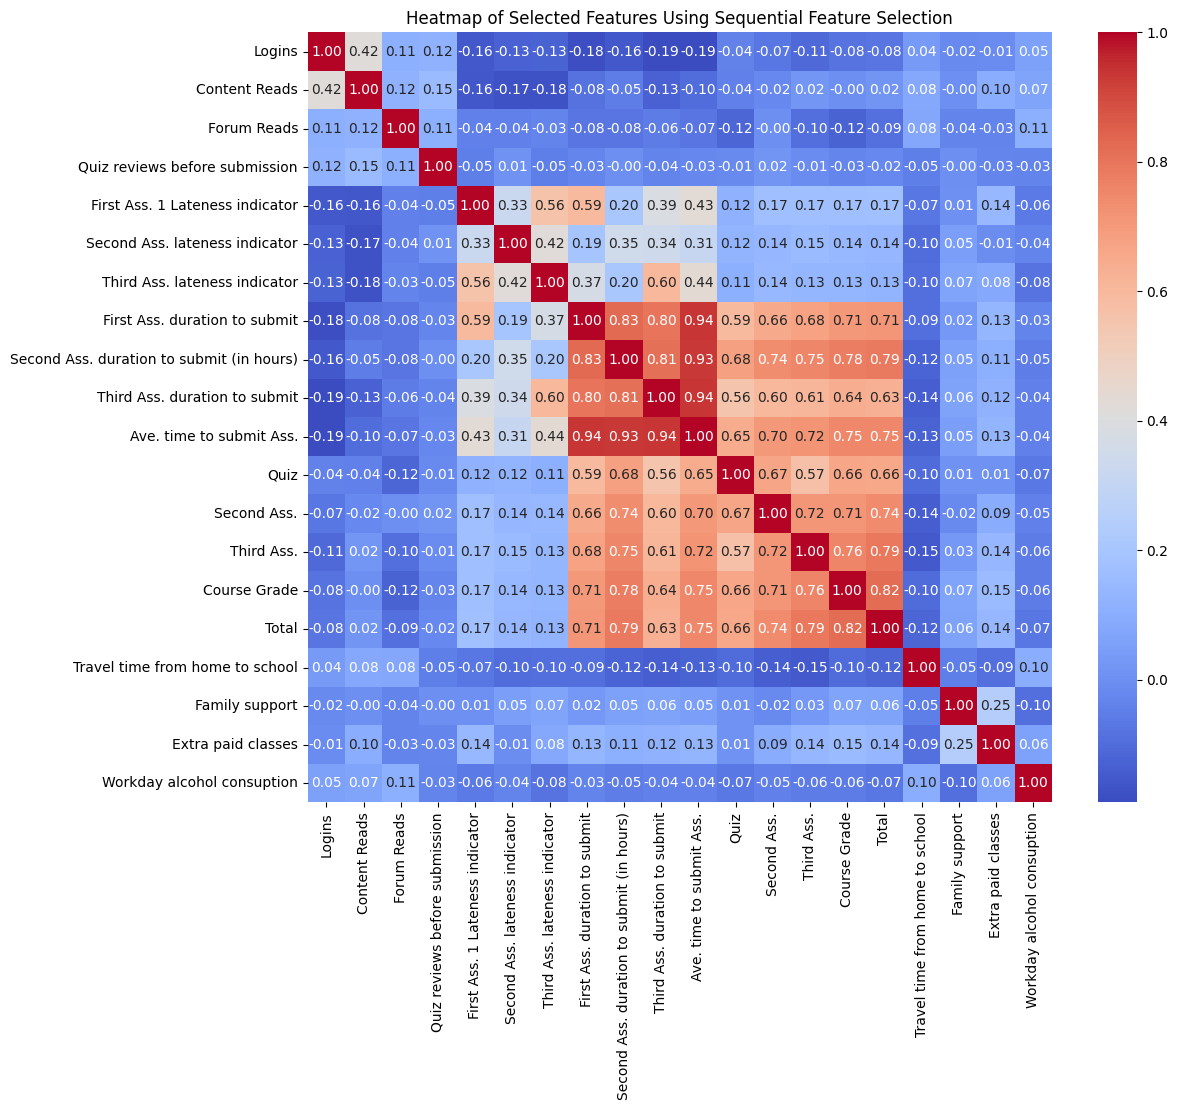

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training LSTM model with SFS selected features...

Evaluating LSTM model with SFS selected features on the test set...
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step

LSTM Model with SFS Selected Features:
Accuracy: 0.6014
Precision: 0.6323
Recall: 0.6014
F1-measure: 0.5881

Classification Report (SFS):
              precision    recall  f1-score   support

           F       0.70      0.42      0.53        78
           P       0.55      0.80      0.65        70

    accuracy                           0.60       148
   macro avg       0.63      0.61      0.59       148
weighted avg       0.63      0.60      0.59       148



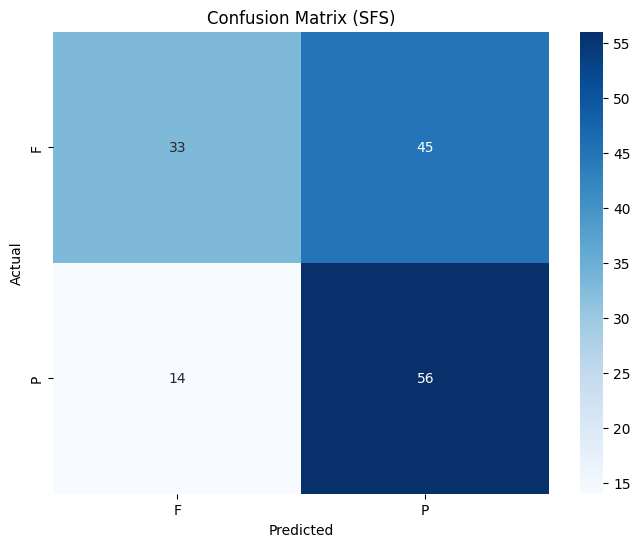

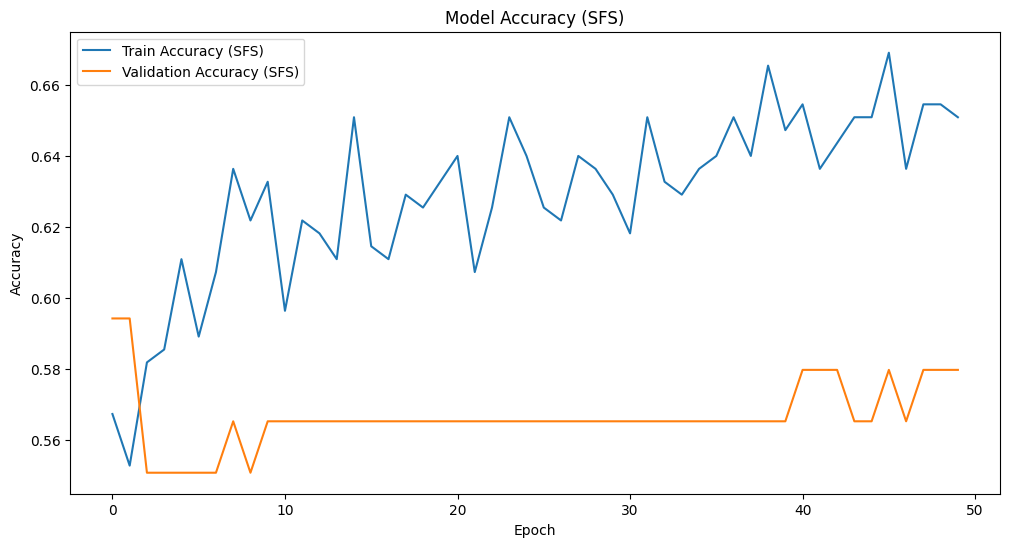

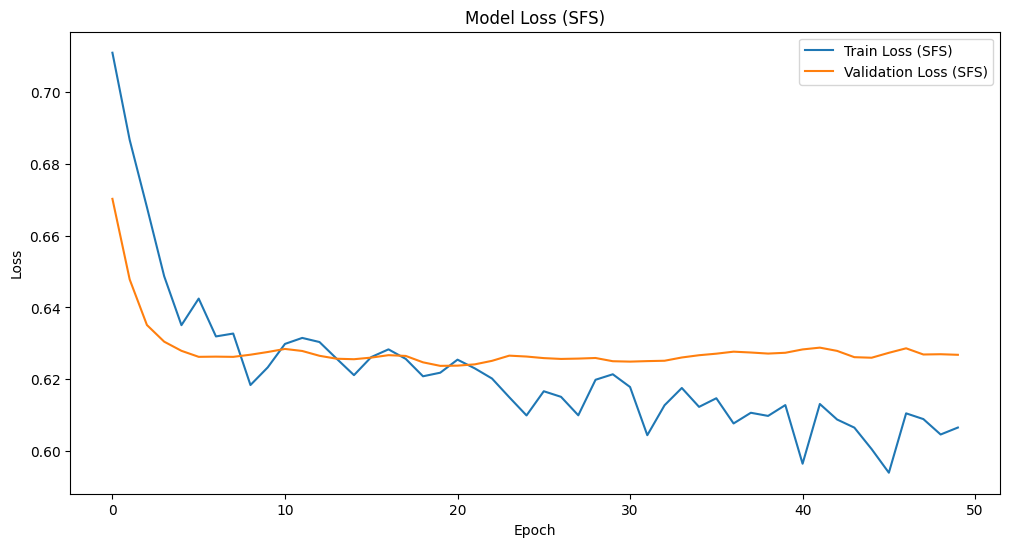

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector
import tensorflow as tf
from sklearn.svm import SVC # Using SVC as the estimator for SFS
from sklearn.metrics import precision_score, recall_score, f1_score

# Ensure TensorFlow is using a fixed seed as well for reproducibility
tf.random.set_seed(42)

# SEQUENTIAL FEATURE SELECTION (SFS)

# Initialize an estimator. SFS wraps around a model.
estimator_sfs = SVC(kernel='linear', random_state=42, probability=True) # probability=True needed if using prediction probabilities

# Initialize Sequential Feature Selector
sfs = SequentialFeatureSelector(
    estimator=estimator_sfs,
    n_features_to_select=20,  # Example: Select top 20 features
    direction='forward',       # Or 'backward'
    cv=5,                      # 5-fold cross-validation
    scoring='accuracy',       # Using accuracy as the evaluation metric for SFS
    n_jobs=-1
)

# Fit SFS on the training data
# SFS internally performs cross-validation on the training set to evaluate feature subsets.
print("Starting Sequential Feature Selection (Forward Selection)... This may take some time.")
sfs.fit(X_train, y_train) # Use the original non-encoded y_train for fitting SFS

# Get the selected features mask
selected_features_mask_sfs = sfs.get_support()

# Get the names of the selected features
selected_features_sfs = X_train.columns[selected_features_mask_sfs]

print("\nSequential Feature Selection (SFS) Results:")
print(f"Selected Features (SFS, Forward Selection):")
print(selected_features_sfs.tolist())

# Get the subset of the training and testing data with selected features from SFS
X_train_sfs = X_train[selected_features_sfs]
X_test_sfs = X_test[selected_features_sfs]

print("\nShape of X_train after SFS:", X_train_sfs.shape)
print("Shape of X_test after SFS:", X_test_sfs.shape)

# Optional: Plot a heatmap of correlations for SFS selected features
corr_matrix_sfs = X_train_sfs.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_sfs, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Sequential Feature Selection')
plt.show()

# LSTM MODEL WITH SEQUENTIAL FEATURE SELECTION

np.random.seed(42)
tf.random.set_seed(42) # Set TensorFlow seed again before model building

# Reshape the data for LSTM (samples, timesteps, features)
X_train_sfs_reshaped = X_train_sfs.values.reshape((X_train_sfs.shape[0], 1, X_train_sfs.shape[1]))
X_test_sfs_reshaped = X_test_sfs.values.reshape((X_test_sfs.shape[0], 1, X_test_sfs.shape[1]))

# Build the LSTM model
model_sfs = Sequential()
# The input_shape should match the reshaped data: (timesteps, number of features)
model_sfs.add(LSTM(50, activation='relu', input_shape=(X_train_sfs_reshaped.shape[1], X_train_sfs_reshaped.shape[2])))
model_sfs.add(Dropout(0.2))
model_sfs.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_sfs.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
print("\nTraining LSTM model with SFS selected features...")
history_sfs = model_sfs.fit(X_train_sfs_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
print("\nEvaluating LSTM model with SFS selected features on the test set...")
y_pred_prob_sfs = model_sfs.predict(X_test_sfs_reshaped)
y_pred_encoded_sfs = (y_pred_prob_sfs > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_sfs = label_encoder_y.inverse_transform(y_pred_encoded_sfs.flatten())

# Calculate evaluation metrics
accuracy_sfs = accuracy_score(y_test, y_pred_sfs)
precision_sfs = precision_score(y_test, y_pred_sfs, average='weighted') # Use weighted average for multi-class/imbalanced
recall_sfs = recall_score(y_test, y_pred_sfs, average='weighted')
f1_sfs = f1_score(y_test, y_pred_sfs, average='weighted')

print("\nLSTM Model with SFS Selected Features:")
print(f"Accuracy: {accuracy_sfs:.4f}")
print(f"Precision: {precision_sfs:.4f}")
print(f"Recall: {recall_sfs:.4f}")
print(f"F1-measure: {f1_sfs:.4f}")

# Classification Report
print("\nClassification Report (SFS):")
print(classification_report(y_test, y_pred_sfs))

# Confusion Matrix
cm_sfs = confusion_matrix(y_test, y_pred_sfs)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_sfs, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (SFS)')
plt.show()

# Plot training and validation accuracy for SFS model
plt.figure(figsize=(12, 6))
plt.plot(history_sfs.history['accuracy'], label='Train Accuracy (SFS)')
plt.plot(history_sfs.history['val_accuracy'], label='Validation Accuracy (SFS)')
plt.title('Model Accuracy (SFS)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for SFS model
plt.figure(figsize=(12, 6))
plt.plot(history_sfs.history['loss'], label='Train Loss (SFS)')
plt.plot(history_sfs.history['val_loss'], label='Validation Loss (SFS)')
plt.title('Model Loss (SFS)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()



Random Forest Feature Importances:
Second Ass. duration to submit (in hours)    0.212109
Ave. time to submit Ass.                     0.192374
Total                                        0.136452
Third Ass. duration to submit                0.093426
First Ass. duration to submit                0.086143
                                               ...   
Father job_at_home                           0.000000
Father job_other                             0.000000
Father job_health                            0.000000
Reason for choice of school_other            0.000000
Guardian_other                               0.000000
Length: 66, dtype: float64

Selected Features (Random Forest, Importance > 0.01):
['Second Ass. duration to submit (in hours)', 'Ave. time to submit Ass.', 'Total', 'Third Ass. duration to submit', 'First Ass. duration to submit', 'First Ass.', 'Course Grade', 'Second Ass.', 'Quiz', 'Midterm Exam', 'Third Ass.']

Selected Features (Random Forest, Top 20):
['Second Ass

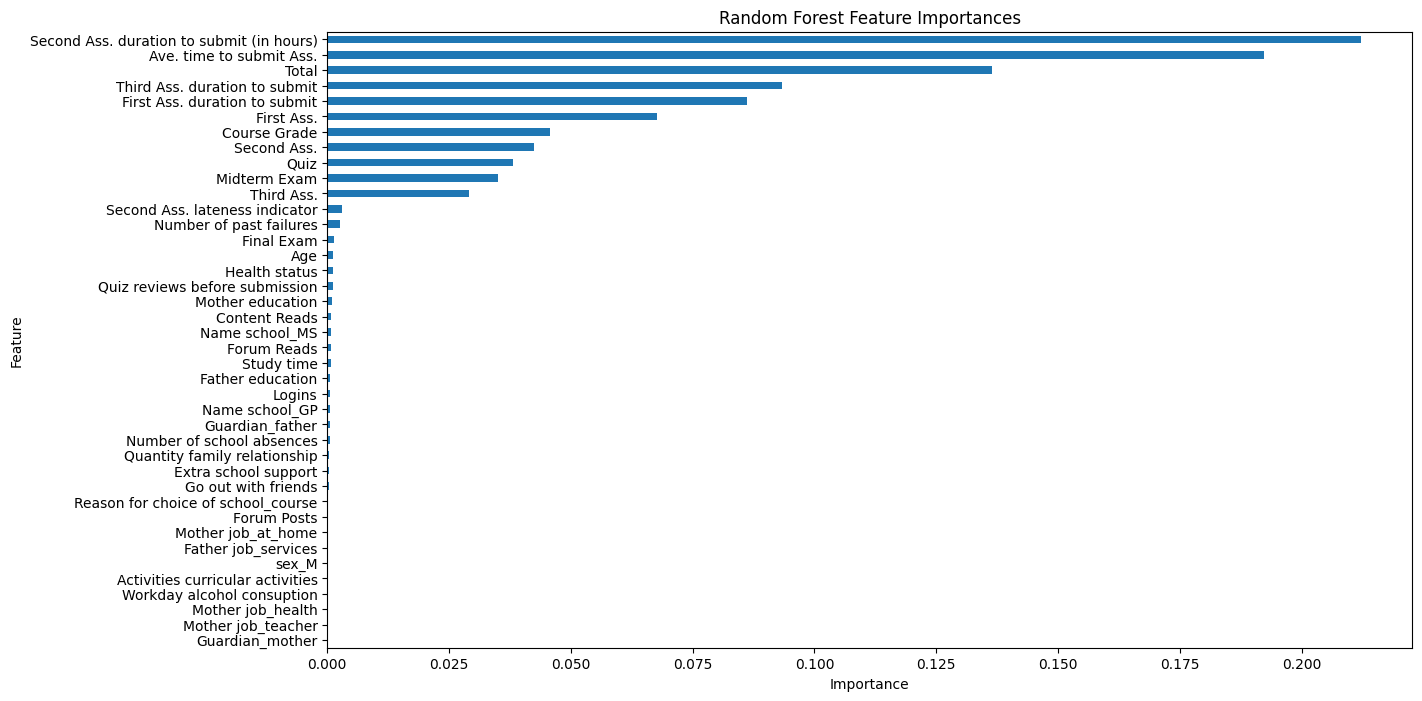

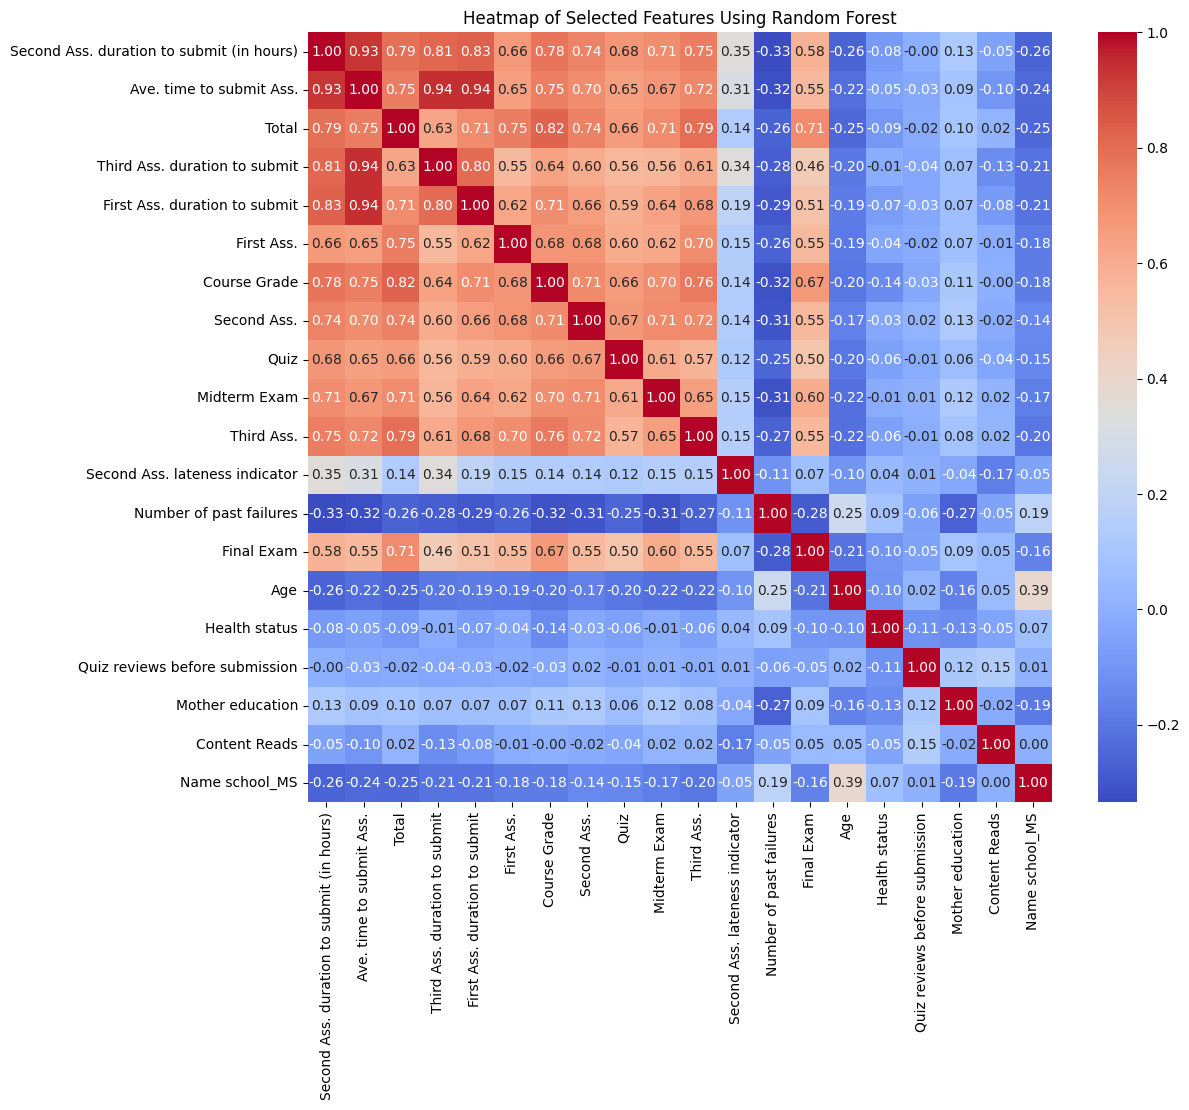

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# RANDOM FOREST FEATURE SELECTION

# Initialize a RandomForestClassifier (or any tree-based model)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the RandomForest model on the training data
rf_model.fit(X_train, y_train)

# Get feature importances
feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)

# Sort the feature importances in descending order
sorted_feature_importances = feature_importances.sort_values(ascending=False)

print("\nRandom Forest Feature Importances:")
print(sorted_feature_importances)

# Select features based on importance
threshold = 0.01 # Example threshold, adjust as needed
selected_features_rf_threshold = sorted_feature_importances[sorted_feature_importances > threshold].index.tolist()

# Example 2: Select the top k features
k_features_to_select_rf = 20 # Example: Select the top 20 features
selected_features_rf_top_k = sorted_feature_importances.head(k_features_to_select_rf).index.tolist()

print(f"\nSelected Features (Random Forest, Importance > {threshold}):")
print(selected_features_rf_threshold)

print(f"\nSelected Features (Random Forest, Top {k_features_to_select_rf}):")
print(selected_features_rf_top_k)

# Get the subset of the training and testing data using one of the selected feature sets
selected_features_rf = selected_features_rf_top_k

X_train_rf = X_train[selected_features_rf]
X_test_rf = X_test[selected_features_rf]

print("\nShape of X_train after Random Forest selection:", X_train_rf.shape)
print("Shape of X_test after Random Forest selection:", X_test_rf.shape)

# Plot the feature importances
plt.figure(figsize=(14, 8))
sorted_feature_importances.head(k_features_to_select_rf * 2).plot(kind='barh') # Plot top 40 for better visualization
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis() # Display the most important feature at the top
plt.show()

# Plot a heatmap of correlations for Random Forest selected features
corr_matrix_rf = X_train_rf.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_rf, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Selected Features Using Random Forest')
plt.show()

LSTM WITH RANDOM FOREST

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training LSTM model with Random Forest selected features...

Evaluating LSTM model with Random Forest selected features on the test set...
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step

LSTM Model with Random Forest Selected Features:
Accuracy: 0.8649
Precision: 0.8726
Recall: 0.8649
F1-measure: 0.8647

Classification Report (Random Forest):
              precision    recall  f1-score   support

           F       0.93      0.81      0.86        78
           P       0.81      0.93      0.87        70

    accuracy                           0.86       148
   macro avg       0.87      0.87      0.86       148
weighted avg       0.87      0.86      0.86       148



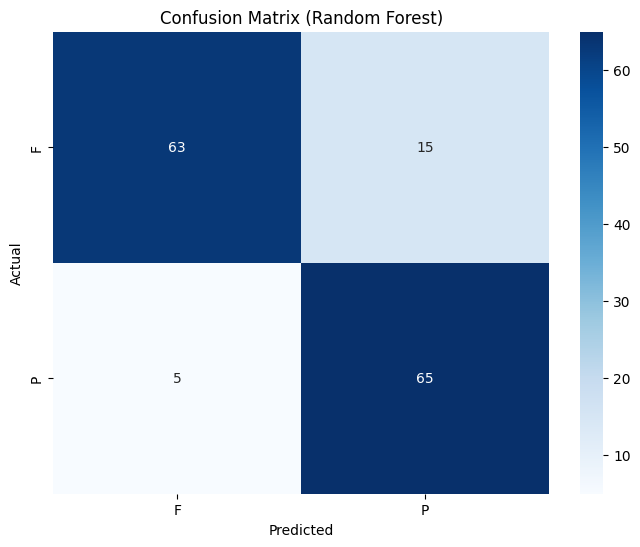

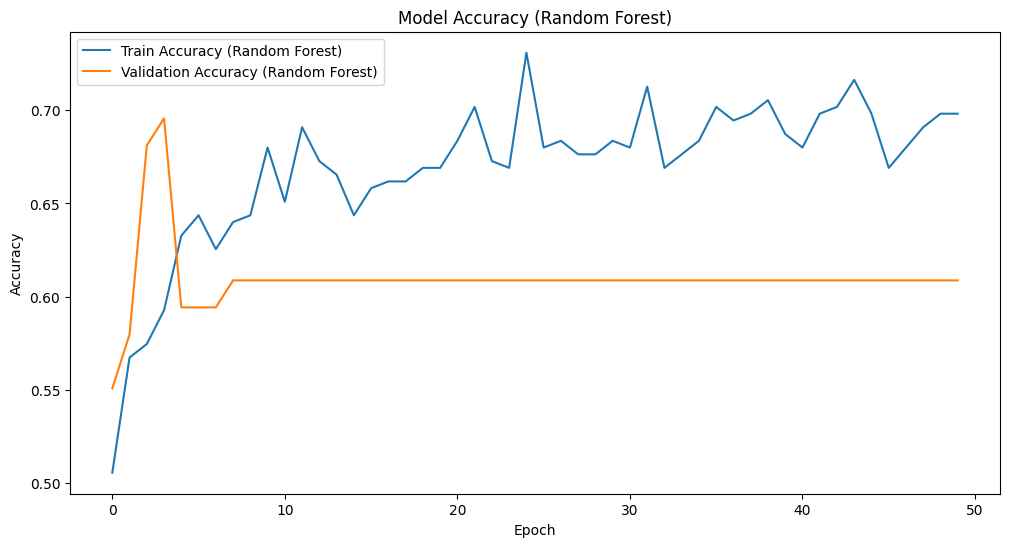

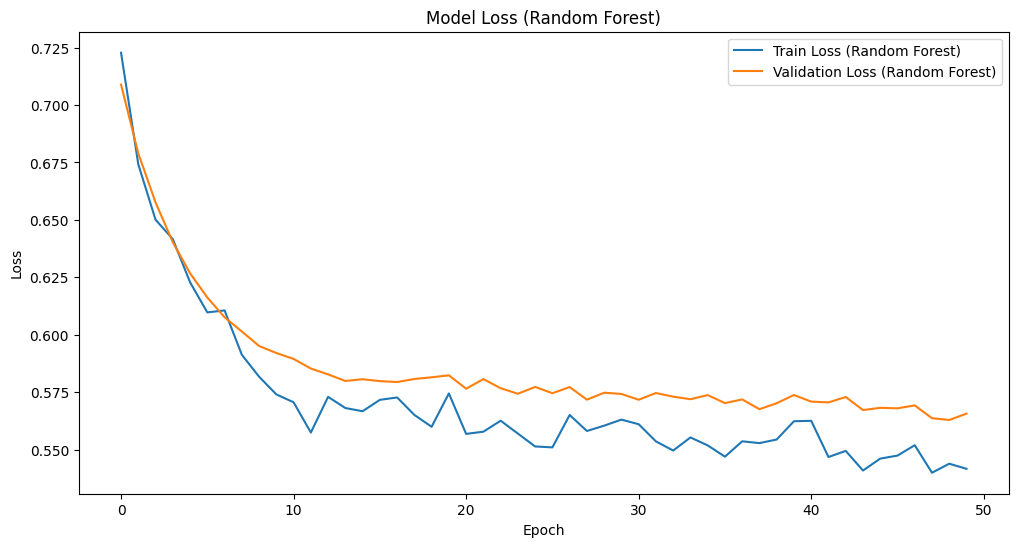

In [ ]:
np.random.seed(42)
tf.random.set_seed(42) # Set TensorFlow seed again before model building

# Reshape the data for LSTM (samples, timesteps, features)
X_train_rf_reshaped = X_train_rf.values.reshape((X_train_rf.shape[0], 1, X_train_rf.shape[1]))
X_test_rf_reshaped = X_test_rf.values.reshape((X_test_rf.shape[0], 1, X_test_rf.shape[1]))

# Build the LSTM model
model_rf = Sequential()
# The input_shape should match the reshaped data: (timesteps, number of features)
model_rf.add(LSTM(50, activation='relu', input_shape=(X_train_rf_reshaped.shape[1], X_train_rf_reshaped.shape[2])))
model_rf.add(Dropout(0.2))
model_rf.add(Dense(1, activation='sigmoid')) # Use sigmoid for binary classification

# Compile the model
model_rf.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
print("\nTraining LSTM model with Random Forest selected features...")
history_rf = model_rf.fit(X_train_rf_reshaped, y_train_encoded, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

# Evaluate the model on the test set
print("\nEvaluating LSTM model with Random Forest selected features on the test set...")
y_pred_prob_rf = model_rf.predict(X_test_rf_reshaped)
y_pred_encoded_rf = (y_pred_prob_rf > 0.5).astype(int) # Convert probabilities to binary predictions

# Decode predictions back to original labels
y_pred_rf = label_encoder_y.inverse_transform(y_pred_encoded_rf.flatten())

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted') # Use weighted average for multi-class/imbalanced
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print("\nLSTM Model with Random Forest Selected Features:")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-measure: {f1_rf:.4f}")

# Classification Report
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder_y.classes_, yticklabels=label_encoder_y.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Random Forest)')
plt.show()

# Plot training and validation accuracy for Random Forest model
plt.figure(figsize=(12, 6))
plt.plot(history_rf.history['accuracy'], label='Train Accuracy (Random Forest)')
plt.plot(history_rf.history['val_accuracy'], label='Validation Accuracy (Random Forest)')
plt.title('Model Accuracy (Random Forest)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss for Random Forest model
plt.figure(figsize=(12, 6))
plt.plot(history_rf.history['loss'], label='Train Loss (Random Forest)')
plt.plot(history_rf.history['val_loss'], label='Validation Loss (Random Forest)')
plt.title('Model Loss (Random Forest)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


DOMAIN-AWARE HYBRID FEATURE SELECTION FRAMEWORK (DAHFS)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, KBinsDiscretizer
from sklearn.feature_selection import mutual_info_classif, chi2, f_classif
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample
from sklearn.metrics.pairwise import rbf_kernel
import warnings
warnings.filterwarnings("ignore")

# -------------------------
# Parameters
# -------------------------
B_BOOTSTRAP = 50
TAU = 0.6
MAX_WRAPPER_FINAL = 20
SEED = 42

# -------------------------
# Load dataset
# -------------------------
df = pd.read_csv("Student Engagement_Pilot_AUGMENTED.csv")

# Encode target -> convert to numpy array immediately
df['Class'] = LabelEncoder().fit_transform(df['Class'])
y = df['Class'].values   # <-- numpy array, avoids Series.reshape error
X = df.drop(columns=['Class'])

# Separate categorical and numeric
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

# One-hot encode categorical columns (keeps consistent column names)
if len(cat_cols) > 0:
    X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
else:
    X_encoded = X.copy()

# Convert boolean columns to integer (if any)
for col in X_encoded.columns:
    if X_encoded[col].dtype == 'bool':
        X_encoded[col] = X_encoded[col].astype(int)

# Scale numerical columns (only those that exist after encoding)
num_cols_after = [c for c in num_cols if c in X_encoded.columns]
if len(num_cols_after) > 0:
    scaler = StandardScaler()
    X_encoded[num_cols_after] = scaler.fit_transform(X_encoded[num_cols_after])

# Ensure X_encoded is a DataFrame
X_encoded = pd.DataFrame(X_encoded, columns=X_encoded.columns)

# -------------------------
# Scoring Functions
# -------------------------
def filter_scores(X_df, y_arr):
    X_np = X_df.values
    mi = mutual_info_classif(X_np, y_arr, random_state=SEED)
    # chi2 requires non-negative; use abs() as a pragmatic workaround
    chi2_scores, _ = chi2(np.abs(X_np), y_arr)
    f_scores, _ = f_classif(X_np, y_arr)
    return (mi + chi2_scores + f_scores) / 3.0

def embedded_scores(X_df, y_arr):
    X_np = X_df.values
    lasso = LassoCV(cv=5, random_state=SEED).fit(X_np, y_arr)
    lasso_scores = np.abs(lasso.coef_)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_np, y_arr)
    rf_scores = rf.feature_importances_
    return (lasso_scores + rf_scores) / 2.0

def interaction_scores(X_df, y_arr):
    """
    Interaction-aware score defined as average of:
      - PMI (mutual information between discretized single feature and y)
      - HSIC (kernel-based dependence between feature and y)

    This function returns a numpy array of length n_features.
    """
    n, p = X_df.shape
    scores_pmi = np.zeros(p, dtype=float)
    scores_hsic = np.zeros(p, dtype=float)

    # PMI: discretize each feature and compute MI(feature, y)
    kb = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")
    for i in range(p):
        col = X_df.iloc[:, i].to_numpy().reshape(-1, 1)
        # handle constant columns gracefully
        if np.unique(col).shape[0] <= 1:
            scores_pmi[i] = 0.0
        else:
            try:
                col_disc = kb.fit_transform(col)
                # mutual_info_classif expects 2D X; we pass the single discretized column
                scores_pmi[i] = mutual_info_classif(col_disc, y_arr, random_state=SEED).mean()
            except Exception:
                scores_pmi[i] = 0.0

    # HSIC: kernel-based dependence between each feature and y
    # Use RBF kernel for continuous features; compute kernel on y as well.
    # convert y to 2D
    Y = np.asarray(y_arr).reshape(-1, 1)
    # Use gamma = 1.0 / (2 * sigma^2). We use default sigma=1 -> gamma=0.5
    Ky = rbf_kernel(Y, Y, gamma=0.5)
    # center Ky (optional but not necessary since we'll normalize later)
    n_samples = Y.shape[0]
    H = np.eye(n_samples) - np.ones((n_samples, n_samples)) / n_samples
    Ky_centered = H.dot(Ky).dot(H)

    for i in range(p):
        Xi = X_df.iloc[:, i].to_numpy().reshape(-1, 1)
        # if constant, HSIC 0
        if np.unique(Xi).shape[0] <= 1:
            scores_hsic[i] = 0.0
            continue
        Kx = rbf_kernel(Xi, Xi, gamma=0.5)
        Kx_centered = H.dot(Kx).dot(H)
        # empirical HSIC (trace(Kx H Ky H) / (n-1)^2). we use (n)^2 denom as pragmatic
        try:
            hsic_val = np.trace(Kx_centered.dot(Ky_centered)) / ((n_samples - 1.0)**2 + 1e-12)
        except Exception:
            hsic_val = 0.0
        scores_hsic[i] = hsic_val

    # combine PMI + HSIC
    scores = (scores_pmi + scores_hsic) / 2.0
    return scores

# -------------------------
# DAHFS (Single Run)
# -------------------------
def dahfs_once(X_df, y_arr):
    # Step 1: compute the three families of scores
    f_scores = filter_scores(X_df, y_arr)       # filter-based
    e_scores = embedded_scores(X_df, y_arr)     # embedded-based
    i_scores = interaction_scores(X_df, y_arr)  # PMI+HSIC

    # Step 2: normalize each to [0,1]
    def norm_arr(a):
        a = np.asarray(a, dtype=float)
        rng = np.ptp(a)
        if rng == 0:
            return np.zeros_like(a)
        return (a - np.min(a)) / (rng + 1e-12)

    f_scores = norm_arr(f_scores)
    e_scores = norm_arr(e_scores)
    i_scores = norm_arr(i_scores)

    # Step 3: hybrid fusion (weights can be tuned)
    beta_F, beta_E, beta_I = 0.33, 0.33, 0.34
    fused = beta_F * f_scores + beta_E * e_scores + beta_I * i_scores

    # Step 4: redundancy pruning by correlation clusters (rho > 0.85)
    cols = X_df.columns.tolist()
    corr = X_df.corr().abs().values  # p x p matrix
    keep = np.ones(len(cols), dtype=bool)
    for i in range(len(cols)):
        if not keep[i]:
            continue
        for j in range(i+1, len(cols)):
            if keep[j] and corr[i, j] > 0.85:
                # keep feature with higher fused score
                if fused[i] >= fused[j]:
                    keep[j] = False
                else:
                    keep[i] = False
                    break

    selected_cols = [c for k, c in zip(keep, cols) if k]
    return selected_cols, fused[keep]

# -------------------------
# Stability Selection over bootstrap runs
# -------------------------
def dahfs_stability(X_df, y_arr, B=B_BOOTSTRAP, tau=TAU, max_final=MAX_WRAPPER_FINAL):
    feature_counts = pd.Series(0.0, index=X_df.columns)

    print(f"Running DAHFS stability selection: B={B}, tau={tau}, max_final={max_final}")
    for b in range(B):
        if (b+1) % 10 == 0:
            print(f"  Bootstrap iteration {b+1}/{B}")
        X_res, y_res = resample(X_df, y_arr, replace=True, random_state=SEED + b)
        selected, _ = dahfs_once(X_res, y_res)
        # increment counts for selected features
        feature_counts[selected] += 1.0

    freq = feature_counts / B
    stable = freq[freq >= tau].sort_values(ascending=False)

    if len(stable) == 0 and len(freq) > 0:
        print(f"No features met tau={tau}. Selecting top {max_final} by frequency.")
        stable = freq.sort_values(ascending=False).head(max_final)
    elif len(stable) > max_final:
        print(f"More than {max_final} features met tau={tau}. Truncating to top {max_final}.")
        stable = stable.head(max_final)

    return stable

# -------------------------
# Run the DAHFS stability procedure
# -------------------------
stable_features = dahfs_stability(X_encoded, y, B=B_BOOTSTRAP, tau=TAU, max_final=MAX_WRAPPER_FINAL)

print("\nFinal Stable Features Selected (DAHFS):")
print(stable_features)

Running DAHFS stability selection: B=50, tau=0.6, max_final=20
  Bootstrap iteration 10/50
  Bootstrap iteration 20/50
  Bootstrap iteration 30/50
  Bootstrap iteration 40/50
  Bootstrap iteration 50/50
More than 20 features met tau=0.6. Truncating to top 20.

Final Stable Features Selected (DAHFS):
 ID                                          1.0
Logins                                       1.0
Content Reads                                1.0
Forum Reads                                  1.0
Forum Posts                                  1.0
Quiz reviews before submission               1.0
First Ass. 1 Lateness indicator              1.0
Second Ass. lateness indicator               1.0
Third Ass. lateness indicator                1.0
Second Ass. duration to submit (in hours)    1.0
Quiz                                         1.0
First Ass.                                   1.0
Midterm Exam                                 1.0
Second Ass.                                  1.0
Final Exam   

VISUALISATION OF SELECTED FEATURES BY DAFHS

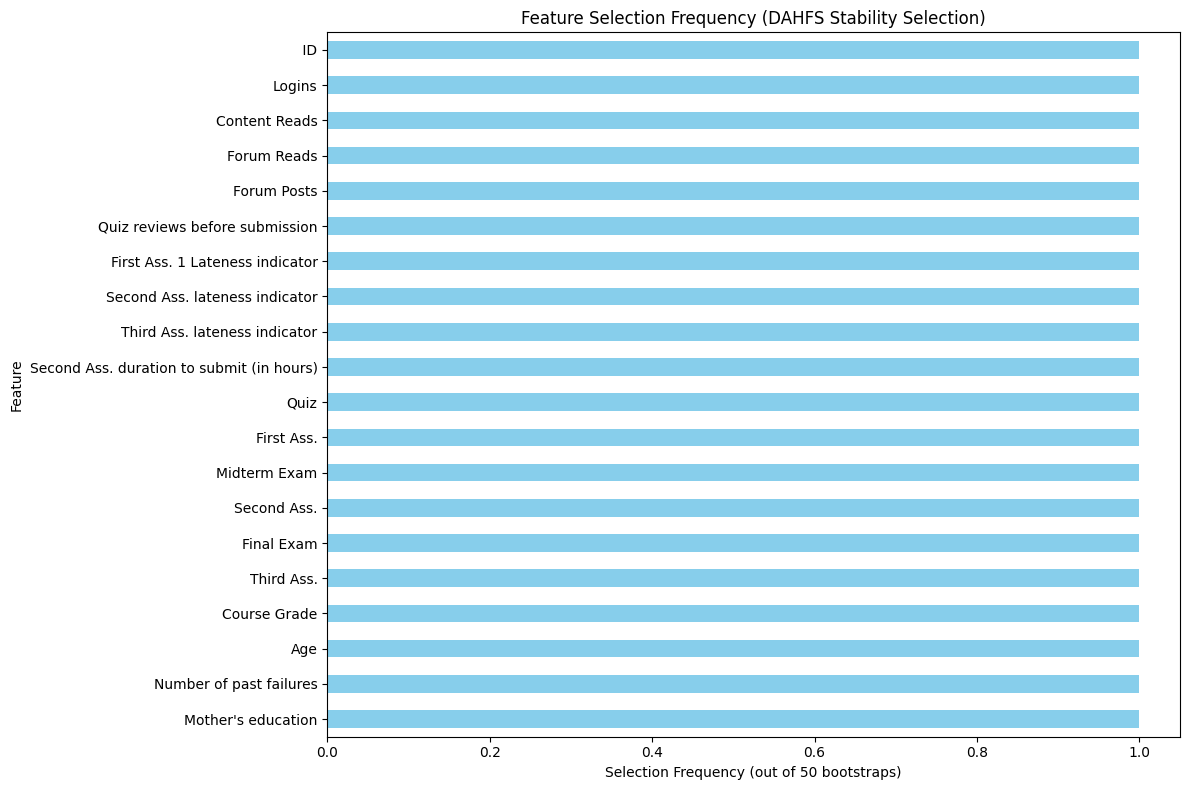

In [ ]:
if not stable_features.empty:
    plt.figure(figsize=(12, 8))
    stable_features.plot(kind='barh', color='skyblue')
    plt.title('Feature Selection Frequency (DAHFS Stability Selection)')
    plt.xlabel('Selection Frequency (out of {} bootstraps)'.format(B_BOOTSTRAP))
    plt.ylabel('Feature')
    plt.gca().invert_yaxis() # Show the most frequently selected features at the top
    plt.tight_layout()
    plt.show()
else:
    print("No stable features were selected by DAHFS.")

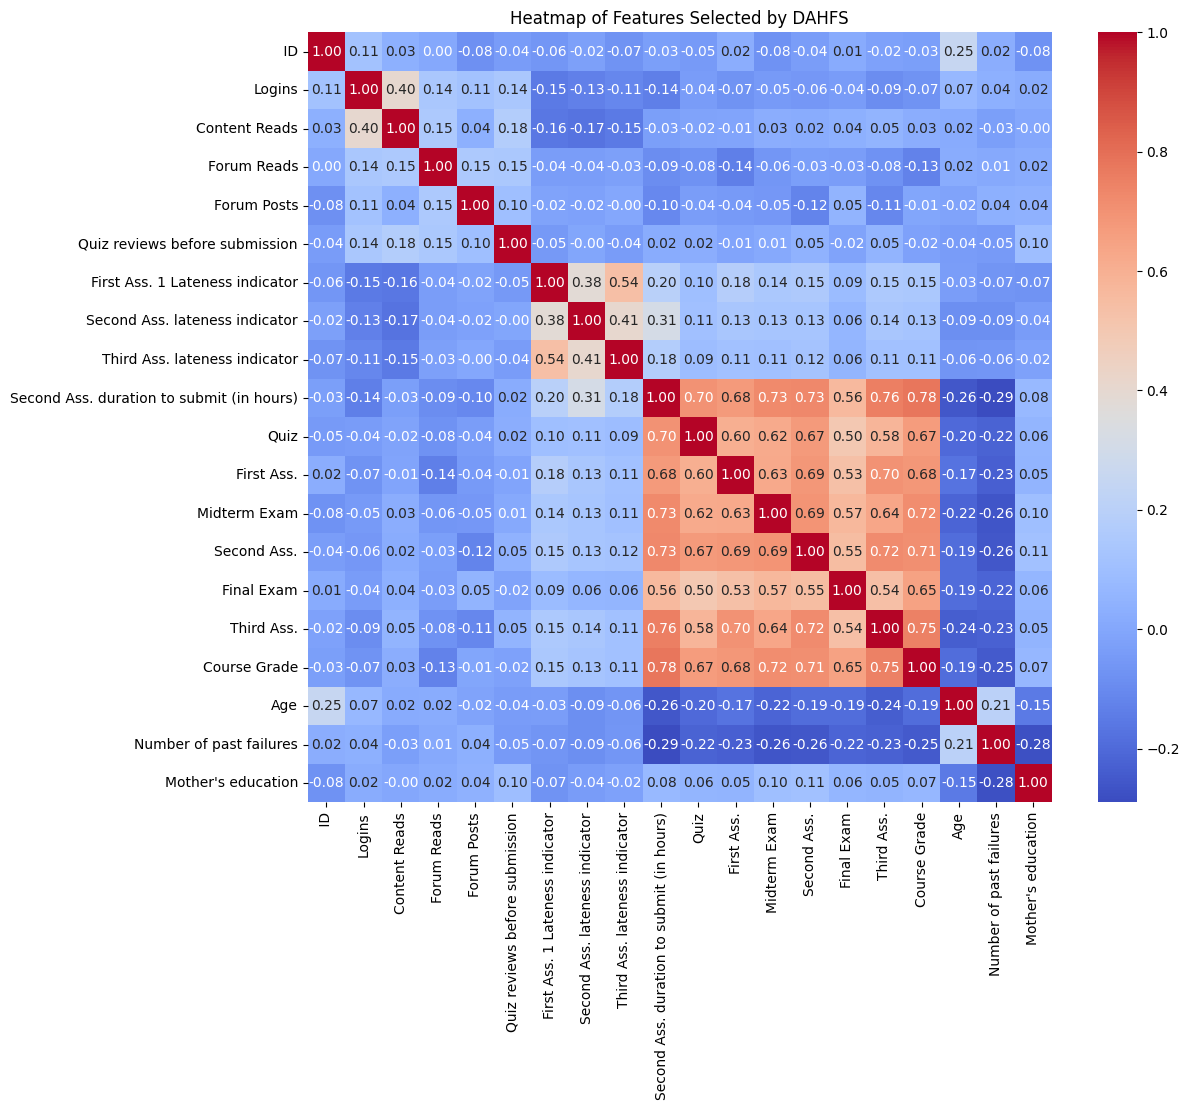

In [ ]:
# Get the subset of the DataFrame with only the stable features
X_stable = X_encoded[stable_features.index] # Use .index to get the feature names from the Series

# Calculate the correlation matrix
corr_matrix_dahfs = X_stable.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_dahfs, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap of Features Selected by DAHFS')
plt.show()

LSTM MODEL WITH DAFHS FEATURES

Training LSTM model with DAHFS selected features...
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.5316 - loss: 0.6916 - val_accuracy: 0.9620 - val_loss: 0.6208
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9644 - loss: 0.5989 - val_accuracy: 0.9873 - val_loss: 0.5393
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9897 - loss: 0.5081 - val_accuracy: 0.9873 - val_loss: 0.4507
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9897 - loss: 0.4055 - val_accuracy: 0.9873 - val_loss: 0.3548
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9856 - loss: 0.3019 - val_accuracy: 0.9873 - val_loss: 0.2624
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9914 - loss: 0.2020 - val_accuracy: 0.9873 - val_loss: 0.1862
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9914 - loss: 0.1392 - val_accuracy: 0.9873 - val_loss: 0.1318
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accura

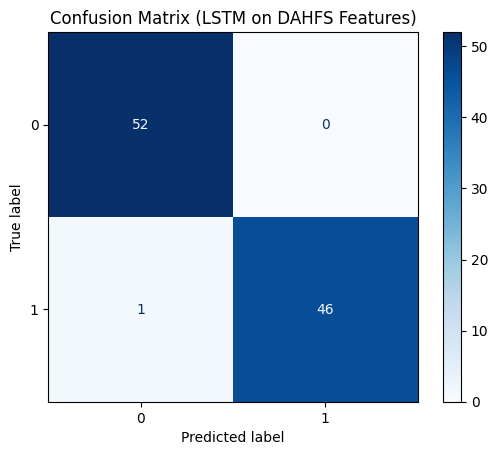

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# -------------------------
# Load dataset
# -------------------------
df = pd.read_csv("Student Engagement_Pilot_AUGMENTED.csv")

# Drop the ' ID' column (note the leading space in the original data)
if ' ID' in df.columns:
    df.drop([' ID'], axis=1, inplace=True)
# Also check for 'ID' without space in case of inconsistent naming
elif 'ID' in df.columns:
     df.drop(['ID'], axis=1, inplace=True)


# Encode target
df['Class'] = LabelEncoder().fit_transform(df['Class'])  # P=1, F=0
y = df['Class']
X = df.drop(columns=['Class'])

# One-hot encode categorical features
X = pd.get_dummies(X, drop_first=True)

# Scale features (already done in previous cells, keep this for consistency but note it's redundant if running the whole notebook)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns) # Update X to be the scaled DataFrame

# -------------------------
# Use DAHFS stable features
# -------------------------
stable_features = ['Logins', 'Content Reads', 'Forum Reads', 'Forum Posts', 'Quiz reviews before submission', 'First Ass. 1 Lateness indicator', 'Second Ass. lateness indicator', 'Third Ass. lateness indicator', 'Second Ass. duration to submit (in hours)', 'Quiz', 'First Ass.', 'Midterm Exam', 'Second Ass.', 'Final Exam', 'Third Ass.', 'Course Grade', 'Age', 'Number of past failures', "Mother's education"]


X_selected = X[stable_features]

# -------------------------
# Train/Test Split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# Reshape for LSTM: (samples, timesteps, features)
X_train = np.expand_dims(X_train.values, axis=1)
X_test = np.expand_dims(X_test.values, axis=1)

# Ensure target y is a 1D numpy array for binary classification
num_classes = len(np.unique(y))
if num_classes == 2:
    y_train = y_train.values.astype(np.float32) # Use float32 for binary_crossentropy
    y_test = y_test.values.astype(np.float32) # Use float32 for binary_crossentropy
else:
     # Convert labels to categorical for multi-class (>2 classes)
    y_train = to_categorical(y_train, num_classes=num_classes)
    y_test = to_categorical(y_test, num_classes=num_classes)


# -------------------------
# Build LSTM Model
# -------------------------
model = Sequential()
# The input_shape should be (timesteps, number of features)
model.add(LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False))
model.add(Dropout(0.3))
model.add(Dense(32, activation="relu"))
# Output layer: 1 unit with sigmoid for binary
if num_classes == 2:
    model.add(Dense(1, activation="sigmoid")) # Single unit for binary classification
    loss_function = "binary_crossentropy"
else:
    model.add(Dense(num_classes, activation="softmax")) # num_classes units for multi-class
    loss_function = "categorical_crossentropy"


model.compile(
    loss=loss_function,
    optimizer="adam",
    metrics=["accuracy"]
)

# -------------------------
# Train
# -------------------------
print("Training LSTM model with DAHFS selected features...")
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=1
)

# -------------------------
# Evaluation
# -------------------------
print("\nEvaluating LSTM model with DAHFS selected features on the test set...")
y_pred_probs = model.predict(X_test)
if num_classes > 2:
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y_test, axis=1)
else:
    y_pred = (y_pred_probs > 0.5).astype(int).flatten()
    y_true = y_test.flatten().astype(int) # Ensure y_true is integer and flattened


acc = accuracy_score(y_true, y_pred)
# For binary classification, precision_score, recall_score, f1_score need average specified
# Use 'binary' for binary classification if target is 0/1, or 'weighted' for imbalanced
prec = precision_score(y_true, y_pred, average="binary" if num_classes == 2 else "weighted")
rec = recall_score(y_true, y_pred, average="binary" if num_classes == 2 else "weighted")
f1 = f1_score(y_true, y_pred, average="binary" if num_classes == 2 else "weighted")


print("\nEvaluation Metrics:")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")

# -------------------------
# Confusion Matrix
# -------------------------
cm = confusion_matrix(y_true, y_pred)
# Ensure labels for ConfusionMatrixDisplay are correct for binary case
labels = LabelEncoder().fit(df['Class']).classes_ if num_classes == 2 else np.unique(y_true)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (LSTM on DAHFS Features)")
plt.show()

SHAP PLOTS OF LSTM WITH DAFHS

Initializing SHAP Explainer...
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Calculating SHAP values for test data...


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
6519/6519 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step
1/1 ━━━━━━━━━━━━

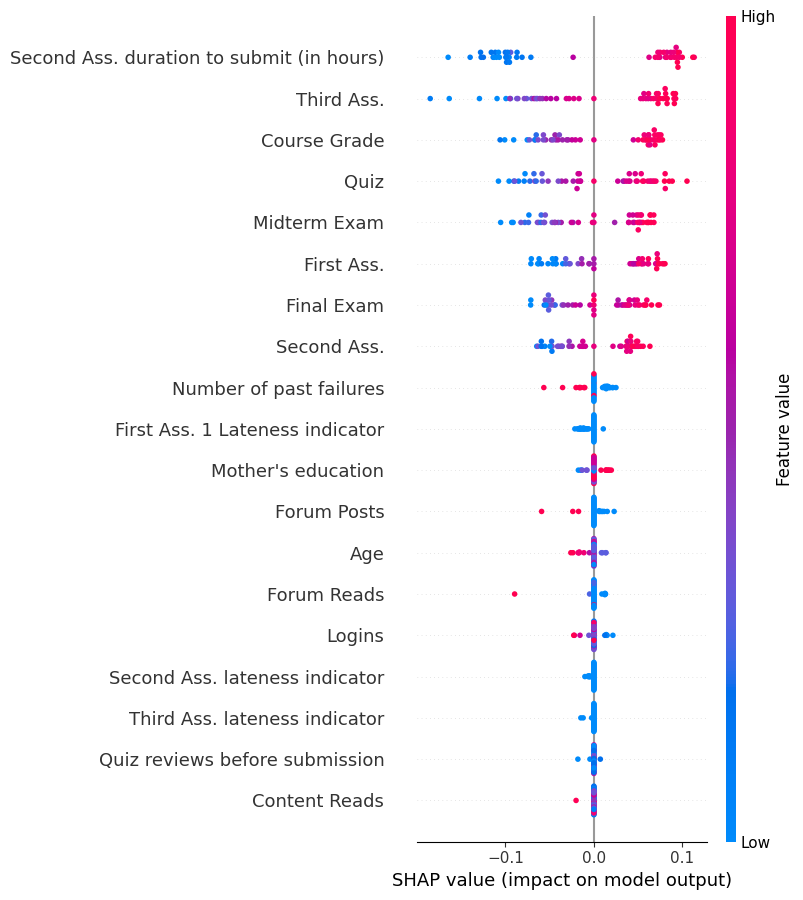


Generating SHAP Dependence Plot for: Second Ass. duration to submit (in hours)


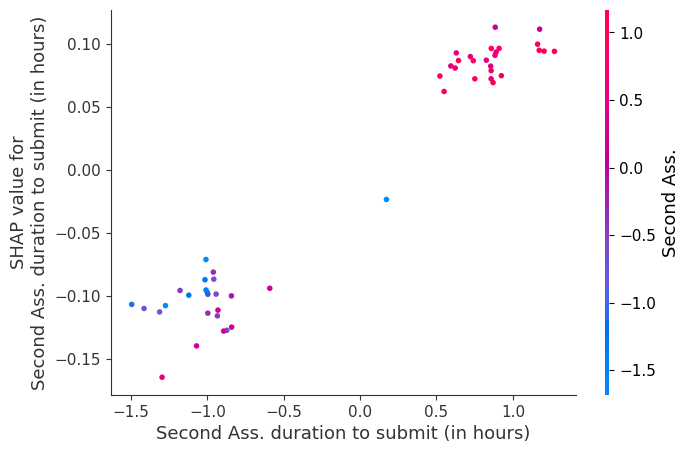


Generating SHAP Force Plot for instance index 0 in the test sample...



Generating SHAP Force Plot for multiple instances (interactive)...



Generating SHAP Decision Plot...


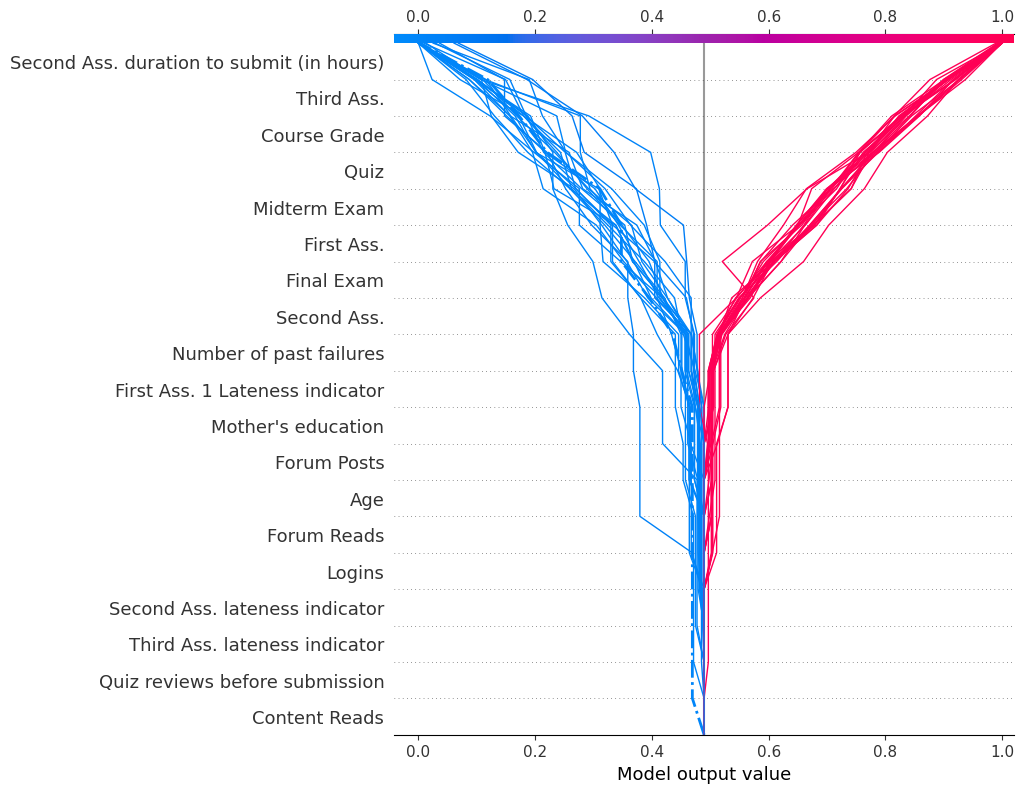


SHAP Analysis complete.


In [ ]:
!pip install shap -q

import shap

X_train_2d = X_train.reshape(X_train.shape[0], X_train.shape[2])
X_test_2d = X_test.reshape(X_test.shape[0], X_test.shape[2])

# Need the feature names for SHAP plots.
feature_names = X_selected.columns.tolist()
X_train_2d_df = pd.DataFrame(X_train_2d, columns=feature_names)
X_test_2d_df = pd.DataFrame(X_test_2d, columns=feature_names)

# Create a background dataset sample
# Reduce the background dataset size for faster computation if needed
background_data = X_train_2d_df.sample(n=min(100, X_train_2d_df.shape[0]), random_state=42)


# Create a SHAP explainer.
def model_predict(X):
    # Reshape input for the LSTM model
    X_reshaped = X.reshape(X.shape[0], 1, X.shape[1])
    # Get the probability of the positive class
    return model.predict(X_reshaped)[:, 0]


# Initialize the explainer.
print("Initializing SHAP Explainer...")
explainer = shap.KernelExplainer(model_predict, background_data)

# Calculate SHAP values for a sample of the test data
print("Calculating SHAP values for test data...")
test_sample_indices = np.random.choice(X_test_2d_df.shape[0], size=min(50, X_test_2d_df.shape[0]), replace=False)
test_sample_data = X_test_2d_df.iloc[test_sample_indices]

# Get original y_true values for the test sample for comparison
y_true_sample = y_true[test_sample_indices]

shap_values = explainer.shap_values(test_sample_data)

print("SHAP value calculation complete.")

# -------------------------
# Visualize SHAP Results
# -------------------------

# Summary Plot: shows the overall importance and impact of each feature.
# Color indicates feature value (e.g., high or low).
print("\nGenerating SHAP Summary Plot...")
shap.summary_plot(shap_values, test_sample_data, feature_names=feature_names)

# Dependence Plot: shows the effect of a single feature across the dataset.
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)
most_important_feature_index = np.argmax(mean_abs_shap)
most_important_feature_name = feature_names[most_important_feature_index]

print(f"\nGenerating SHAP Dependence Plot for: {most_important_feature_name}")
shap.dependence_plot(most_important_feature_name, shap_values, test_sample_data, feature_names=feature_names)


# Force Plot (for a single instance): visualizes how features push the prediction
instance_index_to_explain = 0
print(f"\nGenerating SHAP Force Plot for instance index {instance_index_to_explain} in the test sample...")

shap.initjs() # Initialize JavaScript for interactive plots
shap.force_plot(explainer.expected_value, shap_values[instance_index_to_explain,:], test_sample_data.iloc[instance_index_to_explain,:], feature_names=feature_names)

print("\nGenerating SHAP Force Plot for multiple instances (interactive)...")
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values, test_sample_data, feature_names=feature_names)


# Decision Plot: shows how each feature contributes to the prediction path for one or more instances.
print("\nGenerating SHAP Decision Plot...")
# Can plot multiple instances for comparison.
shap.decision_plot(explainer.expected_value, shap_values, test_sample_data, feature_names=feature_names, highlight=0) # Highlight the first instance


print("\nSHAP Analysis complete.")